In [1]:
# Step 1: Imports and project configuration

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root from the notebooks directory
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
CLEANED_DATA_DIR = DATA_DIR / "cleaned"
REPORTS_DIR = PROJECT_ROOT / "reports"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data exists:", RAW_DATA_DIR.exists())
print("Cleaned data exists:", CLEANED_DATA_DIR.exists())
print("Reports directory exists:", REPORTS_DIR.exists())

Project root: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab
Raw data exists: True
Cleaned data exists: False
Reports directory exists: True


In [2]:
# Step 2: Inspect available data files

for folder in [RAW_DATA_DIR, DATA_DIR]:
    print(f"\nFolder: {folder}")

    if folder.exists():
        files = list(folder.iterdir())
        print("Items found:", len(files))

        for path in files[:15]:
            print(" -", path.name)
    else:
        print("Folder does not exist")

# Check for processed CSV files anywhere in the project
print("\nProcessed CSV files:")
for path in PROJECT_ROOT.rglob("*.csv"):
    if ".venv" not in path.parts:
        print(" -", path.relative_to(PROJECT_ROOT))


Folder: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\data\raw
Items found: 1246
 - 1082591.yaml
 - 1082592.yaml
 - 1082593.yaml
 - 1082594.yaml
 - 1082595.yaml
 - 1082596.yaml
 - 1082597.yaml
 - 1082598.yaml
 - 1082599.yaml
 - 1082600.yaml
 - 1082601.yaml
 - 1082602.yaml
 - 1082603.yaml
 - 1082604.yaml
 - 1082605.yaml

Folder: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\data
Items found: 2
 - processed
 - raw

Processed CSV files:


In [4]:
# Step 3: Inspect the processed data directory

PROCESSED_DIR = DATA_DIR / "processed"

for path in sorted(PROCESSED_DIR.rglob("*")):
    if path.is_file():
        print(
            f"{path.relative_to(PROJECT_ROOT)}"
            f" | {path.stat().st_size / 1024:.1f} KB"
        )

In [5]:
# Step 4: Diagnose the empty processed folder

print("Processed folder exists:", PROCESSED_DIR.exists())
print("Processed folder contents:", list(PROCESSED_DIR.iterdir()))

print("\nOther project files:")
for path in sorted(PROJECT_ROOT.iterdir()):
    print(path.name, " [folder]" if path.is_dir() else " [file]")

print("\nNotebook files:")
for path in PROJECT_ROOT.rglob("*.ipynb"):
    if ".venv" not in path.parts and "ipynb_checkpoints" not in str(path):
        print(path.relative_to(PROJECT_ROOT))

Processed folder exists: True
Processed folder contents: []

Other project files:
.venv  [folder]
data  [folder]
notebooks  [folder]
reports  [folder]
requirements.txt  [file]
src  [folder]
tests  [folder]

Notebook files:
notebooks\01_data_profiling.ipynb
notebooks\02_advanced_predictive_modelling.ipynb


In [6]:
# Step 5: Inspect existing source files

for folder_name in ["src", "tests"]:
    folder = PROJECT_ROOT / folder_name
    print(f"\n{'=' * 20} {folder_name} {'=' * 20}")

    for path in sorted(folder.rglob("*.py")):
        print(path.relative_to(PROJECT_ROOT))


==================== src ====================
src\data\audit_raw.py
src\data\inspect_yaml.py

==================== tests ====================


In [7]:
# Step 6: Read the existing raw-data audit script

audit_script = PROJECT_ROOT / "src" / "data" / "audit_raw.py"

print(audit_script.read_text(encoding="utf-8"))


from pathlib import Path
from collections import Counter
from datetime import date, datetime

import yaml

DATA_DIR = Path("data/raw")


def get_match_date(info):
    dates = info.get("dates", [])

    if not dates:
        return None

    value = dates[0]

    if isinstance(value, (date, datetime)):
        return value.date() if isinstance(value, datetime) else value

    try:
        return date.fromisoformat(str(value))
    except ValueError:
        return None


def extract_innings(match):
    """Support the innings structure in the uploaded Cricsheet YAML."""
    for innings_entry in match.get("innings", []) or []:
        if not isinstance(innings_entry, dict):
            continue

        # Older Cricsheet YAML: {"1st innings": {...}}
        for innings_name, innings_data in innings_entry.items():
            if not isinstance(innings_data, dict):
                continue

            team = innings_data.get("team", "Unknown")

            # Older structure: innings_data["

In [8]:
# Step 7: Read the existing YAML inspection script

inspect_script = PROJECT_ROOT / "src" / "data" / "inspect_yaml.py"

print(inspect_script.read_text(encoding="utf-8"))


from pathlib import Path
import yaml
from pprint import pprint

DATA_DIR = Path("data/raw")

files = sorted(DATA_DIR.rglob("*.yaml"))
if not files:
    files = sorted(DATA_DIR.rglob("*.yml"))

if not files:
    raise FileNotFoundError("No YAML files found.")

file_path = files[0]

with file_path.open("r", encoding="utf-8") as f:
    match = yaml.safe_load(f)

print("FILE:", file_path.name)
print("\nTOP-LEVEL KEYS:")
print(list(match.keys()))

print("\nINFO KEYS:")
info = match.get("info", {})
print(list(info.keys()))

print("\nSEASON:")
print(info.get("season", "Not present at info.season"))

print("\nEVENT:")
pprint(info.get("event"))

print("\nFIRST INNINGS STRUCTURE:")
innings = match.get("innings", [])
pprint(innings[0] if innings else "No innings found", depth=5)

print("\nFIRST DELIVERY:")
if innings:
    first_innings = innings[0]
    if isinstance(first_innings, dict):
        innings_details = next(iter(first_innings.values()))
        if isinstance(innings_details, dict):
  

In [9]:
# Step 8: Load raw Cricsheet YAML matches

import yaml
from collections import Counter

yaml_files = sorted(RAW_DATA_DIR.rglob("*.yaml"))
yaml_files += sorted(RAW_DATA_DIR.rglob("*.yml"))

matches_raw = []
load_errors = []

for file_path in yaml_files:
    try:
        with file_path.open("r", encoding="utf-8") as file:
            match = yaml.safe_load(file)

        if isinstance(match, dict) and isinstance(match.get("info"), dict):
            matches_raw.append({
                "match_id": file_path.stem,
                "file_path": file_path,
                "match": match,
            })
        else:
            load_errors.append((file_path.name, "Invalid YAML structure"))

    except Exception as exc:
        load_errors.append((file_path.name, str(exc)))

print("YAML files discovered:", len(yaml_files))
print("Matches loaded:", len(matches_raw))
print("Files with errors:", len(load_errors))

if matches_raw:
    sample = matches_raw[0]
    print("\nSample match ID:", sample["match_id"])
    print("Info keys:", list(sample["match"]["info"].keys()))
    print("Innings count:", len(sample["match"].get("innings", [])))

if load_errors:
    print("\nFirst 5 errors:", load_errors[:5])

YAML files discovered: 1243
Matches loaded: 1243
Files with errors: 0

Sample match ID: 1082591
Info keys: ['balls_per_over', 'city', 'competition', 'dates', 'gender', 'match_type', 'outcome', 'overs', 'player_of_match', 'players', 'registry', 'teams', 'toss', 'umpires', 'venue', 'team_type']
Innings count: 2


In [10]:
# Step 9: Inspect innings and delivery structure

sample_match = matches_raw[0]["match"]

for innings_number, innings_entry in enumerate(
    sample_match.get("innings", []), start=1
):
    print(f"\n--- Innings {innings_number} ---")
    print("Entry type:", type(innings_entry).__name__)

    if isinstance(innings_entry, dict):
        innings_name = next(iter(innings_entry))
        innings_data = innings_entry[innings_name]

        print("Innings key:", innings_name)
        print("Innings data keys:", list(innings_data.keys()))
        print("Batting team:", innings_data.get("team"))
        print("Overs recorded:", len(innings_data.get("overs", [])))

        if innings_data.get("overs"):
            first_over = innings_data["overs"][0]
            print("First over keys:", list(first_over.keys()))
            print("Deliveries in first over:", len(first_over.get("deliveries", [])))

            if first_over.get("deliveries"):
                print("First delivery:")
                print(first_over["deliveries"][0])


--- Innings 1 ---
Entry type: dict
Innings key: 1st innings
Innings data keys: ['team', 'deliveries']
Batting team: Sunrisers Hyderabad
Overs recorded: 0

--- Innings 2 ---
Entry type: dict
Innings key: 2nd innings
Innings data keys: ['team', 'deliveries', 'target']
Batting team: Royal Challengers Bangalore
Overs recorded: 0


In [11]:
# Step 10: Inspect delivery records in the actual YAML format

first_innings_data = sample_match["innings"][0]["1st innings"]
deliveries = first_innings_data["deliveries"]

print("Delivery entries:", len(deliveries))
print("\nFirst three delivery entries:")

for entry in deliveries[:3]:
    print(entry)

print("\nFirst delivery entry type:", type(deliveries[0]).__name__)
print("First delivery entry keys:", list(deliveries[0].keys()))

Delivery entries: 125

First three delivery entries:
{0.1: {'actual_delivery': '0.1', 'batsman': 'DA Warner', 'bowler': 'TS Mills', 'non_striker': 'S Dhawan', 'runs': {'batsman': 0, 'extras': 0, 'total': 0}}}
{0.2: {'actual_delivery': '0.2', 'batsman': 'DA Warner', 'bowler': 'TS Mills', 'non_striker': 'S Dhawan', 'runs': {'batsman': 0, 'extras': 0, 'total': 0}}}
{0.3: {'actual_delivery': '0.3', 'batsman': 'DA Warner', 'bowler': 'TS Mills', 'non_striker': 'S Dhawan', 'runs': {'batsman': 4, 'extras': 0, 'total': 4}}}

First delivery entry type: dict
First delivery entry keys: [0.1]


In [12]:
# Step 11: Extract delivery records from a match

def extract_match_deliveries(match_record):
    """Convert one Cricsheet match into ordered delivery-level records."""
    match = match_record["match"]
    match_id = match_record["match_id"]
    info = match.get("info", {})

    records = []

    for innings_number, innings_entry in enumerate(
        match.get("innings", []), start=1
    ):
        if not isinstance(innings_entry, dict):
            continue

        for innings_name, innings_data in innings_entry.items():
            if not isinstance(innings_data, dict):
                continue

            batting_team = innings_data.get("team", "Unknown")

            # Older Cricsheet format: deliveries stored directly in a list
            deliveries = innings_data.get("deliveries", [])

            for sequence, entry in enumerate(deliveries, start=1):
                if not isinstance(entry, dict) or not entry:
                    continue

                delivery_label, delivery = next(iter(entry.items()))

                if not isinstance(delivery, dict):
                    continue

                runs = delivery.get("runs", {}) or {}
                extras = delivery.get("extras", {}) or {}

                wickets = delivery.get("wickets")
                if wickets is None:
                    wicket = delivery.get("wicket")
                    wickets = [wicket] if isinstance(wicket, dict) else []

                records.append({
                    "match_id": match_id,
                    "date": (
                        info.get("dates", [None])[0]
                        if info.get("dates") else None
                    ),
                    "innings": innings_number,
                    "innings_name": innings_name,
                    "delivery_sequence": sequence,
                    "delivery_label": str(
                        delivery.get("actual_delivery", delivery_label)
                    ),
                    "batting_team": batting_team,
                    "batter": delivery.get(
                        "batter", delivery.get("batsman")
                    ),
                    "bowler": delivery.get("bowler"),
                    "batter_runs": runs.get(
                        "batter", runs.get("batsman", 0)
                    ) or 0,
                    "total_runs": runs.get("total", 0) or 0,
                    "extras": runs.get("extras", 0) or 0,
                    "wides": extras.get("wides", 0) or 0,
                    "noballs": extras.get("noballs", 0) or 0,
                    "byes": extras.get("byes", 0) or 0,
                    "legbyes": extras.get("legbyes", 0) or 0,
                    "penalty": extras.get("penalty", 0) or 0,
                    "wicket_count": len(wickets),
                    "wicket_details": wickets,
                })

    return records


sample_records = extract_match_deliveries(matches_raw[0])
sample_deliveries_df = pd.DataFrame(sample_records)

print("Extracted delivery rows:", len(sample_deliveries_df))
print("Columns:", sample_deliveries_df.columns.tolist())
display(sample_deliveries_df.head(5))

Extracted delivery rows: 248
Columns: ['match_id', 'date', 'innings', 'innings_name', 'delivery_sequence', 'delivery_label', 'batting_team', 'batter', 'bowler', 'batter_runs', 'total_runs', 'extras', 'wides', 'noballs', 'byes', 'legbyes', 'penalty', 'wicket_count', 'wicket_details']


,match_id,date,innings,innings_name,delivery_sequence,delivery_label,batting_team,batter,bowler,batter_runs,total_runs,extras,wides,noballs,byes,legbyes,penalty,wicket_count,wicket_details
0,1082591,2017-04-05,1,1st innings,1,0.1,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,0,0,0,0,0,0,[]
1,1082591,2017-04-05,1,1st innings,2,0.2,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,0,0,0,0,0,0,[]
2,1082591,2017-04-05,1,1st innings,3,0.3,Sunrisers Hyderabad,DA Warner,TS Mills,4,4,0,0,0,0,0,0,0,[]
3,1082591,2017-04-05,1,1st innings,4,0.4,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,0,0,0,0,0,0,[]
4,1082591,2017-04-05,1,1st innings,5,0.5,Sunrisers Hyderabad,DA Warner,TS Mills,0,2,2,2,0,0,0,0,0,[]


In [13]:
# Step 12: Validate extracted totals against the raw match

for innings_number, innings_entry in enumerate(
    sample_match.get("innings", []), start=1
):
    innings_name, innings_data = next(iter(innings_entry.items()))
    batting_team = innings_data.get("team", "Unknown")

    raw_deliveries = innings_data.get("deliveries", [])

    raw_runs = 0
    raw_wickets = 0

    for entry in raw_deliveries:
        if not isinstance(entry, dict) or not entry:
            continue

        _, delivery = next(iter(entry.items()))
        runs = delivery.get("runs", {}) or {}
        raw_runs += runs.get("total", 0) or 0

        wickets = delivery.get("wickets")
        if wickets is None:
            wicket = delivery.get("wicket")
            wickets = [wicket] if isinstance(wicket, dict) else []

        raw_wickets += len(wickets)

    extracted = sample_deliveries_df[
        sample_deliveries_df["innings"] == innings_number
    ]

    extracted_runs = extracted["total_runs"].sum()
    extracted_wickets = extracted["wicket_count"].sum()

    print(f"\nInnings {innings_number}: {batting_team}")
    print("Raw delivery count:", len(raw_deliveries))
    print("Extracted delivery count:", len(extracted))
    print("Raw total runs:", raw_runs)
    print("Extracted total runs:", extracted_runs)
    print("Runs match:", raw_runs == extracted_runs)
    print("Raw wicket events:", raw_wickets)
    print("Extracted wicket events:", extracted_wickets)
    print("Wickets match:", raw_wickets == extracted_wickets)


Innings 1: Sunrisers Hyderabad
Raw delivery count: 125
Extracted delivery count: 125
Raw total runs: 207
Extracted total runs: 207
Runs match: True
Raw wicket events: 4
Extracted wicket events: 4
Wickets match: True

Innings 2: Royal Challengers Bangalore
Raw delivery count: 123
Extracted delivery count: 123
Raw total runs: 172
Extracted total runs: 172
Runs match: True
Raw wicket events: 10
Extracted wicket events: 10
Wickets match: True


In [14]:
# Step 13: Audit innings and delivery structures across all matches

from collections import Counter

innings_count = Counter()
innings_formats = Counter()
missing_delivery_lists = []
empty_innings = []
invalid_innings_entries = []

for match_record in matches_raw:
    match_id = match_record["match_id"]
    innings_list = match_record["match"].get("innings", [])

    innings_count[len(innings_list)] += 1

    for innings_number, innings_entry in enumerate(innings_list, start=1):
        if not isinstance(innings_entry, dict) or not innings_entry:
            invalid_innings_entries.append((match_id, innings_number))
            continue

        innings_name, innings_data = next(iter(innings_entry.items()))

        if not isinstance(innings_data, dict):
            invalid_innings_entries.append((match_id, innings_number))
            continue

        if "deliveries" in innings_data:
            innings_formats["deliveries"] += 1
        elif "overs" in innings_data:
            innings_formats["overs"] += 1
        else:
            innings_formats["unknown"] += 1
            missing_delivery_lists.append(
                (match_id, innings_number, innings_name, list(innings_data.keys()))
            )

        deliveries = innings_data.get("deliveries", [])

        if not deliveries:
            empty_innings.append((match_id, innings_number, innings_name))

print("Matches loaded:", len(matches_raw))
print("\nInnings per match:")
print(innings_count)

print("\nInnings data formats:")
print(innings_formats)

print("\nInvalid innings entries:", len(invalid_innings_entries))
print("Innings with missing delivery lists:", len(missing_delivery_lists))
print("Innings with empty/missing deliveries:", len(empty_innings))

if missing_delivery_lists:
    print("\nExamples of innings with unexpected structures:")
    print(missing_delivery_lists[:5])

if invalid_innings_entries:
    print("\nExamples of invalid innings entries:")
    print(invalid_innings_entries[:5])

Matches loaded: 1243

Innings per match:
Counter({2: 1221, 4: 15, 1: 6, 6: 1})

Innings data formats:
Counter({'deliveries': 2514})

Invalid innings entries: 0
Innings with missing delivery lists: 0
Innings with empty/missing deliveries: 0


In [16]:
# Step 14: Extract delivery-level data from every match

all_delivery_records = []
extraction_errors = []

for match_record in matches_raw:
    try:
        records = extract_match_deliveries(match_record)
        all_delivery_records.extend(records)
    except Exception as exc:
        extraction_errors.append({
            "match_id": match_record["match_id"],
            "error": str(exc),
        })

deliveries_df = pd.DataFrame(all_delivery_records)

print("Matches attempted:", len(matches_raw))
print("Matches with extraction errors:", len(extraction_errors))
print("Total delivery records:", len(deliveries_df))
print("Unique matches in delivery data:", deliveries_df["match_id"].nunique())

print("\nDataFrame shape:", deliveries_df.shape)
print("\nColumns:")
print(deliveries_df.columns.tolist())

print("\nFirst five rows:")
display(deliveries_df.head())

if extraction_errors:
    print("\nFirst extraction errors:")
    print(extraction_errors[:5])

Matches attempted: 1243
Matches with extraction errors: 0
Total delivery records: 295732
Unique matches in delivery data: 1243

DataFrame shape: (295732, 19)

Columns:
['match_id', 'date', 'innings', 'innings_name', 'delivery_sequence', 'delivery_label', 'batting_team', 'batter', 'bowler', 'batter_runs', 'total_runs', 'extras', 'wides', 'noballs', 'byes', 'legbyes', 'penalty', 'wicket_count', 'wicket_details']

First five rows:


,match_id,date,innings,innings_name,delivery_sequence,delivery_label,batting_team,batter,bowler,batter_runs,total_runs,extras,wides,noballs,byes,legbyes,penalty,wicket_count,wicket_details
0,1082591,2017-04-05,1,1st innings,1,0.1,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,0,0,0,0,0,0,[]
1,1082591,2017-04-05,1,1st innings,2,0.2,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,0,0,0,0,0,0,[]
2,1082591,2017-04-05,1,1st innings,3,0.3,Sunrisers Hyderabad,DA Warner,TS Mills,4,4,0,0,0,0,0,0,0,[]
3,1082591,2017-04-05,1,1st innings,4,0.4,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,0,0,0,0,0,0,[]
4,1082591,2017-04-05,1,1st innings,5,0.5,Sunrisers Hyderabad,DA Warner,TS Mills,0,2,2,2,0,0,0,0,0,[]


In [17]:
# Step 15: Full-dataset quality audit

# 1. Missing values in important columns
key_columns = [
    "match_id", "date", "innings", "delivery_sequence",
    "batting_team", "batter", "bowler", "total_runs"
]

print("DATASET QUALITY AUDIT")
print("=" * 50)

print("\n1. Missing values in key columns:")
display(deliveries_df[key_columns].isna().sum().to_frame("missing_count"))

# 2. Duplicate delivery identifiers
duplicate_mask = deliveries_df.duplicated(
    subset=["match_id", "innings", "delivery_sequence"],
    keep=False
)

print("\n2. Duplicate delivery identifiers:", duplicate_mask.sum())

# 3. Run reconciliation
deliveries_df["run_reconciliation_difference"] = (
    deliveries_df["total_runs"]
    - deliveries_df["batter_runs"]
    - deliveries_df["extras"]
)

reconciliation_errors = (
    deliveries_df["run_reconciliation_difference"] != 0
)

print("\n3. Run reconciliation errors:", reconciliation_errors.sum())

# 4. Negative run values
run_columns = [
    "batter_runs", "total_runs", "extras",
    "wides", "noballs", "byes", "legbyes", "penalty"
]

negative_runs = (deliveries_df[run_columns] < 0).any(axis=1)

print("4. Deliveries with negative run values:", negative_runs.sum())

# 5. Unexpected innings and delivery counts
print("\n5. Innings represented:")
display(
    deliveries_df.groupby("innings")
    .agg(
        delivery_records=("match_id", "size"),
        matches=("match_id", "nunique"),
        total_runs=("total_runs", "sum"),
        wicket_events=("wicket_count", "sum")
    )
)

# 6. Overall totals
print("\n6. Overall totals:")
print("Total runs:", deliveries_df["total_runs"].sum())
print("Batter runs:", deliveries_df["batter_runs"].sum())
print("Extras:", deliveries_df["extras"].sum())
print("Wicket events:", deliveries_df["wicket_count"].sum())

print("\nAudit complete.")

DATASET QUALITY AUDIT

1. Missing values in key columns:


,missing_count
match_id,0
date,0
innings,0
delivery_sequence,0
batting_team,0
batter,0
bowler,0
total_runs,0



2. Duplicate delivery identifiers: 0

3. Run reconciliation errors: 0
4. Deliveries with negative run values: 0

5. Innings represented:


,delivery_records,matches,total_runs,wicket_events
innings,,,,
1,153254,1243,209532,7620
2,142303,1237,191891,7054
3,86,16,149,23
4,77,16,140,7
5,8,1,11,1
6,4,1,15,0



6. Overall totals:
Total runs: 401738
Batter runs: 381529
Extras: 20209
Wicket events: 14705

Audit complete.


In [18]:
# Step 16: Investigate matches with unusual innings counts

unusual_match_ids = (
    deliveries_df.groupby("match_id")["innings"]
    .nunique()
    .loc[lambda counts: counts > 2]
    .index
)

unusual_matches = []

for match_record in matches_raw:
    match_id = match_record["match_id"]

    if match_id not in unusual_match_ids:
        continue

    match = match_record["match"]
    info = match.get("info", {})

    unusual_matches.append({
        "match_id": match_id,
        "date": info.get("dates", [None])[0],
        "teams": " vs ".join(info.get("teams", [])),
        "match_type": info.get("match_type"),
        "competition": str(info.get("competition")),
        "outcome": str(info.get("outcome")),
        "innings_count": len(match.get("innings", [])),
        "innings_details": [
            {
                "innings_name": next(iter(entry.keys())),
                "batting_team": next(iter(entry.values())).get("team"),
                "delivery_count": len(
                    next(iter(entry.values())).get("deliveries", [])
                ),
            }
            for entry in match.get("innings", [])
            if isinstance(entry, dict) and entry
        ],
    })

unusual_matches_df = pd.DataFrame(unusual_matches)

print("Matches with more than two innings:", len(unusual_matches_df))
display(unusual_matches_df)

Matches with more than two innings: 16


,match_id,date,teams,match_type,competition,outcome,innings_count,innings_details
0,1082625,2017-04-29,Gujarat Lions vs Mumbai Indians,T20,IPL,"{'eliminator': 'Mumbai Indians', 'result': 'tie'}",4,"[{'innings_name': '1st innings', 'batting_team..."
1,1175365,2019-03-30,Kolkata Knight Riders vs Delhi Capitals,T20,IPL,"{'result': 'tie', 'eliminator': 'Delhi Capitals'}",4,"[{'innings_name': '1st innings', 'batting_team..."
2,1178426,2019-05-02,Mumbai Indians vs Sunrisers Hyderabad,T20,IPL,"{'result': 'tie', 'eliminator': 'Mumbai Indians'}",4,"[{'innings_name': '1st innings', 'batting_team..."
3,1216493,2020-09-20,Delhi Capitals vs Kings XI Punjab,T20,IPL,"{'result': 'tie', 'eliminator': 'Delhi Capitals'}",4,"[{'innings_name': '1st innings', 'batting_team..."
4,1216512,2020-10-18,Kolkata Knight Riders vs Sunrisers Hyderabad,T20,IPL,"{'result': 'tie', 'eliminator': 'Kolkata Knigh...",4,"[{'innings_name': '1st innings', 'batting_team..."
5,1216517,2020-10-18,Mumbai Indians vs Kings XI Punjab,T20,IPL,"{'result': 'tie', 'eliminator': 'Kings XI Punj...",6,"[{'innings_name': '1st innings', 'batting_team..."
6,1216547,2020-09-28,Royal Challengers Bangalore vs Mumbai Indians,T20,IPL,"{'result': 'tie', 'eliminator': 'Royal Challen...",4,"[{'innings_name': '1st innings', 'batting_team..."
7,1254077,2021-04-25,Delhi Capitals vs Sunrisers Hyderabad,T20,IPL,"{'result': 'tie', 'eliminator': 'Delhi Capitals'}",4,"[{'innings_name': '1st innings', 'batting_team..."
8,1473469,2025-04-16,Delhi Capitals vs Rajasthan Royals,T20,IPL,"{'result': 'tie', 'eliminator': 'Delhi Capitals'}",4,"[{'innings_name': '1st innings', 'batting_team..."
9,1529281,2026-04-26,Kolkata Knight Riders vs Lucknow Super Giants,T20,IPL,"{'result': 'tie', 'eliminator': 'Kolkata Knigh...",4,"[{'innings_name': '1st innings', 'batting_team..."


In [19]:
# Step 17: Inspect regular innings and eliminator innings

inspection_ids = ["1082625", "1216517"]

for match_record in matches_raw:
    match_id = match_record["match_id"]

    if match_id not in inspection_ids:
        continue

    match = match_record["match"]
    info = match.get("info", {})

    print("\n" + "=" * 70)
    print("Match ID:", match_id)
    print("Teams:", info.get("teams"))
    print("Outcome:", info.get("outcome"))

    for innings_number, innings_entry in enumerate(
        match.get("innings", []), start=1
    ):
        innings_name, innings_data = next(iter(innings_entry.items()))

        print(
            f"Innings {innings_number}:",
            "Name =", innings_name,
            "| Batting team =", innings_data.get("team"),
            "| Delivery events =", len(innings_data.get("deliveries", []))
        )


Match ID: 1082625
Teams: ['Gujarat Lions', 'Mumbai Indians']
Outcome: {'eliminator': 'Mumbai Indians', 'result': 'tie'}
Innings 1: Name = 1st innings | Batting team = Gujarat Lions | Delivery events = 129
Innings 2: Name = 2nd innings | Batting team = Mumbai Indians | Delivery events = 121
Innings 3: Name = Mumbai Indians Super Over | Batting team = Mumbai Indians | Delivery events = 5
Innings 4: Name = Gujarat Lions Super Over | Batting team = Gujarat Lions | Delivery events = 8

Match ID: 1216517
Teams: ['Mumbai Indians', 'Kings XI Punjab']
Outcome: {'result': 'tie', 'eliminator': 'Kings XI Punjab'}
Innings 1: Name = 1st innings | Batting team = Mumbai Indians | Delivery events = 121
Innings 2: Name = 2nd innings | Batting team = Kings XI Punjab | Delivery events = 124
Innings 3: Name = Kings XI Punjab Super Over | Batting team = Kings XI Punjab | Delivery events = 6
Innings 4: Name = Mumbai Indians Super Over | Batting team = Mumbai Indians | Delivery events = 6
Innings 5: Name = M

In [20]:
# Step 18: Identify regular innings and Super Overs

deliveries_df["is_super_over"] = (
    deliveries_df["innings_name"]
    .str.contains("super over", case=False, na=False)
)

deliveries_df["is_regular_innings"] = (
    deliveries_df["innings_name"]
    .isin(["1st innings", "2nd innings"])
)

print("Delivery classification:")
display(
    deliveries_df.groupby(
        ["innings_name", "is_super_over", "is_regular_innings"],
        dropna=False
    )
    .agg(
        delivery_records=("match_id", "size"),
        matches=("match_id", "nunique"),
        total_runs=("total_runs", "sum"),
        wicket_events=("wicket_count", "sum")
    )
    .reset_index()
)

print("\nRegular-innings delivery records:",
      deliveries_df["is_regular_innings"].sum())

print("Super Over delivery records:",
      deliveries_df["is_super_over"].sum())

print("Other/unclassified delivery records:",
      (~deliveries_df["is_regular_innings"] &
       ~deliveries_df["is_super_over"]).sum())

Delivery classification:


,innings_name,is_super_over,is_regular_innings,delivery_records,matches,total_runs,wicket_events
0,1st innings,False,True,153254,1243,209532,7620
1,2nd innings,False,True,142303,1237,191891,7054
2,Chennai Super Kings Super Over,True,False,5,1,9,2
3,Delhi Capitals Super Over,True,False,19,4,34,1
4,Delhi Daredevils Super Over,True,False,6,1,11,2
5,Gujarat Lions Super Over,True,False,8,1,6,0
6,Kings XI Punjab Super Over,True,False,24,4,47,7
7,Kolkata Knight Riders Super Over,True,False,24,5,40,4
8,Lucknow Super Giants Super Over,True,False,3,1,1,2
9,Mumbai Indians Super Over,True,False,28,4,43,5



Regular-innings delivery records: 295557
Super Over delivery records: 175
Other/unclassified delivery records: 0


In [21]:
# Step 19: Build one row per match

match_rows = []

for match_record in matches_raw:
    match_id = match_record["match_id"]
    match = match_record["match"]
    info = match.get("info", {})
    outcome = info.get("outcome", {}) or {}
    toss = info.get("toss", {}) or {}

    innings_scores = {}

    for innings_entry in match.get("innings", []):
        if not isinstance(innings_entry, dict) or not innings_entry:
            continue

        innings_name, innings_data = next(iter(innings_entry.items()))

        # Exclude Super Overs from regular innings scores
        if innings_name not in ["1st innings", "2nd innings"]:
            continue

        total_runs = sum(
            (delivery.get("runs", {}) or {}).get("total", 0) or 0
            for entry in innings_data.get("deliveries", [])
            if isinstance(entry, dict) and entry
            for delivery in [next(iter(entry.values()))]
            if isinstance(delivery, dict)
        )

        innings_scores[innings_name] = {
            "team": innings_data.get("team"),
            "runs": total_runs,
        }

    first_innings = innings_scores.get("1st innings", {})
    second_innings = innings_scores.get("2nd innings", {})

    winner = outcome.get("winner")

    match_rows.append({
        "match_id": match_id,
        "date": info.get("dates", [None])[0],
        "season": info.get("season"),
        "competition": str(info.get("competition")),
        "match_type": info.get("match_type"),
        "venue": info.get("venue"),
        "city": info.get("city"),
        "team_1": info.get("teams", [None, None])[0],
        "team_2": info.get("teams", [None, None])[1],
        "toss_winner": toss.get("winner"),
        "toss_decision": toss.get("decision"),
        "first_batting_team": first_innings.get("team"),
        "first_innings_runs": first_innings.get("runs"),
        "second_batting_team": second_innings.get("team"),
        "second_innings_runs": second_innings.get("runs"),
        "winner": winner,
        "outcome_result": outcome.get("result"),
        "eliminator_winner": outcome.get("eliminator"),
        "has_first_innings": bool(first_innings),
        "has_second_innings": bool(second_innings),
    })

matches_df = pd.DataFrame(match_rows)

print("Match-level dataset shape:", matches_df.shape)
print("Unique match IDs:", matches_df["match_id"].nunique())

display(matches_df.head())

Match-level dataset shape: (1243, 20)
Unique match IDs: 1243


,match_id,date,season,competition,match_type,venue,city,team_1,team_2,toss_winner,toss_decision,first_batting_team,first_innings_runs,second_batting_team,second_innings_runs,winner,outcome_result,eliminator_winner,has_first_innings,has_second_innings
0,1082591,2017-04-05,None,IPL,T20,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Sunrisers Hyderabad,207,Royal Challengers Bangalore,172.0,Sunrisers Hyderabad,NaN,NaN,True,True
1,1082592,2017-04-06,None,IPL,T20,Maharashtra Cricket Association Stadium,Pune,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,field,Mumbai Indians,184,Rising Pune Supergiant,187.0,Rising Pune Supergiant,NaN,NaN,True,True
2,1082593,2017-04-07,None,IPL,T20,Saurashtra Cricket Association Stadium,Rajkot,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,Gujarat Lions,183,Kolkata Knight Riders,184.0,Kolkata Knight Riders,NaN,NaN,True,True
3,1082594,2017-04-08,None,IPL,T20,Holkar Cricket Stadium,Indore,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,field,Rising Pune Supergiant,163,Kings XI Punjab,164.0,Kings XI Punjab,NaN,NaN,True,True
4,1082595,2017-04-08,None,IPL,T20,M.Chinnaswamy Stadium,Bengaluru,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,Royal Challengers Bangalore,157,Delhi Daredevils,142.0,Royal Challengers Bangalore,NaN,NaN,True,True


In [22]:
# Step 20: Audit match-level completeness

print("Missing values by column:")
display(
    matches_df.isna().sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

print("\nMatch outcome summary:")
print(matches_df["outcome_result"].value_counts(dropna=False))

print("\nFirst innings present:", matches_df["has_first_innings"].sum())
print("Second innings present:", matches_df["has_second_innings"].sum())
print("Winner recorded:", matches_df["winner"].notna().sum())

print("\nMatches missing a second innings or winner:")
incomplete_matches = matches_df[
    (~matches_df["has_second_innings"]) |
    (matches_df["winner"].isna())
]

display(
    incomplete_matches[
        [
            "match_id", "date", "team_1", "team_2",
            "first_innings_runs", "second_innings_runs",
            "winner", "outcome_result", "has_second_innings"
        ]
    ]
)

Missing values by column:


,missing_count
season,1243
eliminator_winner,1227
outcome_result,1218
city,51
winner,25
second_batting_team,6
second_innings_runs,6
match_id,0
competition,0
date,0



Match outcome summary:
outcome_result
NaN          1218
tie            16
no result       9
Name: count, dtype: int64

First innings present: 1243
Second innings present: 1237
Winner recorded: 1218

Matches missing a second innings or winner:


,match_id,date,team_1,team_2,first_innings_runs,second_innings_runs,winner,outcome_result,has_second_innings
33,1082625,2017-04-29,Gujarat Lions,Mumbai Indians,153,153.0,NaN,tie,True
128,1175365,2019-03-30,Kolkata Knight Riders,Delhi Capitals,185,185.0,NaN,tie,True
167,1178424,2019-04-30,Royal Challengers Bangalore,Rajasthan Royals,62,41.0,NaN,no result,True
169,1178426,2019-05-02,Mumbai Indians,Sunrisers Hyderabad,162,162.0,NaN,tie,True
180,1216493,2020-09-20,Delhi Capitals,Kings XI Punjab,157,157.0,NaN,tie,True
199,1216512,2020-10-18,Kolkata Knight Riders,Sunrisers Hyderabad,163,163.0,NaN,tie,True
204,1216517,2020-10-18,Mumbai Indians,Kings XI Punjab,176,176.0,NaN,tie,True
234,1216547,2020-09-28,Royal Challengers Bangalore,Mumbai Indians,201,201.0,NaN,tie,True
258,1254077,2021-04-25,Delhi Capitals,Sunrisers Hyderabad,159,159.0,NaN,tie,True
417,1359519,2023-05-03,Lucknow Super Giants,Chennai Super Kings,125,NaN,NaN,no result,False


In [23]:
# Step 21: Derive season and classify match outcomes

matches_df["date"] = pd.to_datetime(matches_df["date"], errors="coerce")
matches_df["season"] = matches_df["date"].dt.year.astype("Int64")

def classify_match_result(row):
    if pd.notna(row["winner"]):
        return "decisive"
    if row["outcome_result"] == "tie":
        return "tie"
    if row["outcome_result"] == "no result":
        return "no_result"
    return "unknown"

matches_df["match_result_type"] = matches_df.apply(
    classify_match_result,
    axis=1
)

print("Date range:")
print(matches_df["date"].min(), "to", matches_df["date"].max())

print("\nSeason coverage:")
display(
    matches_df.groupby("season")
    .agg(
        matches=("match_id", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
    .reset_index()
)

print("\nMatch result classification:")
display(
    matches_df["match_result_type"]
    .value_counts(dropna=False)
    .to_frame("matches")
)

print("\nMissing season values:", matches_df["season"].isna().sum())

Date range:
2008-04-18 00:00:00 to 2026-05-31 00:00:00

Season coverage:


,season,matches,first_date,last_date
0,2008,58,2008-04-18,2008-06-01
1,2009,57,2009-04-18,2009-05-24
2,2010,60,2010-03-12,2010-04-25
3,2011,73,2011-04-08,2011-05-28
4,2012,74,2012-04-04,2012-05-27
5,2013,76,2013-04-03,2013-05-26
6,2014,60,2014-04-16,2014-06-01
7,2015,59,2015-04-08,2015-05-24
8,2016,60,2016-04-09,2016-05-29
9,2017,59,2017-04-05,2017-05-21



Match result classification:


,matches
match_result_type,
decisive,1218
tie,16
no_result,9



Missing season values: 0


In [24]:
# Step 21: Derive season and classify match outcomes

matches_df["date"] = pd.to_datetime(matches_df["date"], errors="coerce")
matches_df["season"] = matches_df["date"].dt.year.astype("Int64")

def classify_match_result(row):
    if pd.notna(row["winner"]):
        return "decisive"
    if row["outcome_result"] == "tie":
        return "tie"
    if row["outcome_result"] == "no result":
        return "no_result"
    return "unknown"

matches_df["match_result_type"] = matches_df.apply(
    classify_match_result,
    axis=1
)

print("Date range:")
print(matches_df["date"].min(), "to", matches_df["date"].max())

print("\nSeason coverage:")
display(
    matches_df.groupby("season")
    .agg(
        matches=("match_id", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
    .reset_index()
)

print("\nMatch result classification:")
display(
    matches_df["match_result_type"]
    .value_counts(dropna=False)
    .to_frame("matches")
)

print("\nMissing season values:", matches_df["season"].isna().sum())

Date range:
2008-04-18 00:00:00 to 2026-05-31 00:00:00

Season coverage:


,season,matches,first_date,last_date
0,2008,58,2008-04-18,2008-06-01
1,2009,57,2009-04-18,2009-05-24
2,2010,60,2010-03-12,2010-04-25
3,2011,73,2011-04-08,2011-05-28
4,2012,74,2012-04-04,2012-05-27
5,2013,76,2013-04-03,2013-05-26
6,2014,60,2014-04-16,2014-06-01
7,2015,59,2015-04-08,2015-05-24
8,2016,60,2016-04-09,2016-05-29
9,2017,59,2017-04-05,2017-05-21



Match result classification:


,matches
match_result_type,
decisive,1218
tie,16
no_result,9



Missing season values: 0


In [25]:
# Step 22: Prepare first-innings score modelling data

score_df = matches_df.loc[
    matches_df["has_first_innings"]
    & matches_df["first_innings_runs"].notna()
].copy()

score_df = score_df.sort_values("date").reset_index(drop=True)

print("First-innings score dataset")
print("=" * 45)
print("Rows:", len(score_df))
print("Unique matches:", score_df["match_id"].nunique())
print("Missing target values:", score_df["first_innings_runs"].isna().sum())

print("\nTarget distribution:")
display(score_df["first_innings_runs"].describe().to_frame("first_innings_runs"))

print("\nScore ranges:")
print("Minimum score:", score_df["first_innings_runs"].min())
print("Maximum score:", score_df["first_innings_runs"].max())

print("\nFirst five records:")
display(
    score_df[
        [
            "match_id", "date", "season", "venue",
            "first_batting_team", "toss_winner",
            "toss_decision", "first_innings_runs",
            "match_result_type"
        ]
    ].head()
)

First-innings score dataset
Rows: 1243
Unique matches: 1243
Missing target values: 0

Target distribution:


,first_innings_runs
count,1243.000000
mean,168.569590
std,34.053296
min,25.000000
25%,148.000000
50%,168.000000
75%,190.000000
max,287.000000



Score ranges:
Minimum score: 25
Maximum score: 287

First five records:


,match_id,date,season,venue,first_batting_team,toss_winner,toss_decision,first_innings_runs,match_result_type
0,335982,2008-04-18,2008,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,field,222,decisive
1,335983,2008-04-19,2008,"Punjab Cricket Association Stadium, Mohali",Chennai Super Kings,Chennai Super Kings,bat,240,decisive
2,335984,2008-04-19,2008,Feroz Shah Kotla,Rajasthan Royals,Rajasthan Royals,bat,129,decisive
3,335986,2008-04-20,2008,Eden Gardens,Deccan Chargers,Deccan Chargers,bat,110,decisive
4,335985,2008-04-20,2008,Wankhede Stadium,Mumbai Indians,Mumbai Indians,bat,165,decisive


C:\Users\amitb\AppData\Local\Temp\ipykernel_34352\3067430369.py:27: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(


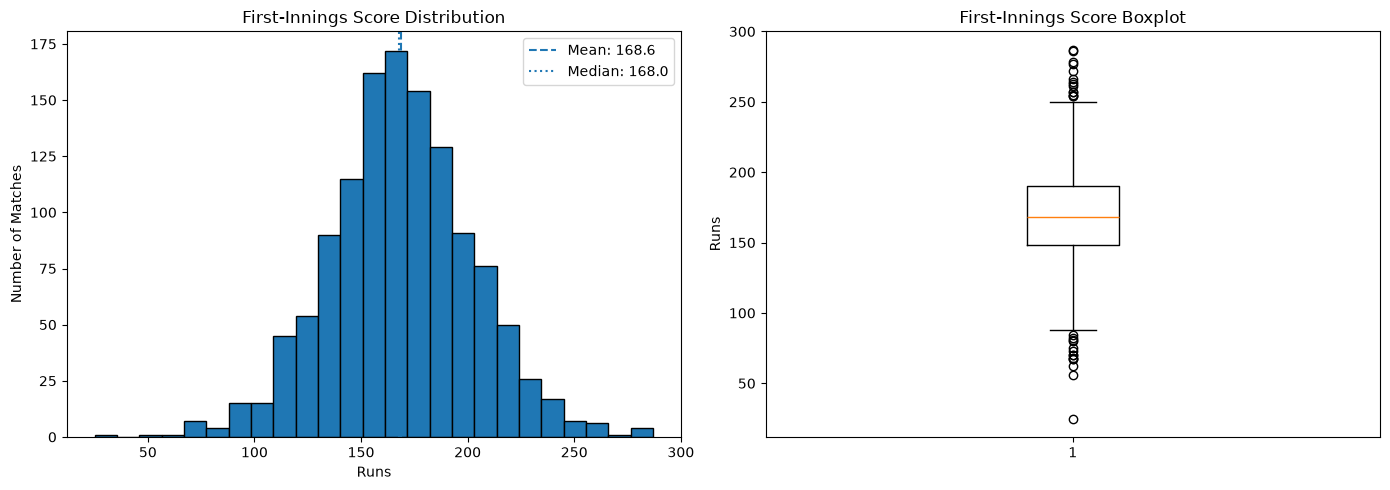

Q1: 148.0
Q3: 190.0
IQR: 42.0
Lower outlier threshold: 85.0
Upper outlier threshold: 253.0
Potential outlier count: 28


,match_id,date,venue,first_batting_team,first_innings_runs
1180,1527685,2026-04-06,"Eden Gardens, Kolkata",Kolkata Knight Riders,25
241,501265,2011-05-21,Feroz Shah Kotla,Delhi Daredevils,56
744,1178424,2019-04-30,M.Chinnaswamy Stadium,Royal Challengers Bangalore,62
612,1082626,2017-04-30,"Punjab Cricket Association IS Bindra Stadium, ...",Delhi Daredevils,67
37,336021,2008-05-16,Wankhede Stadium,Kolkata Knight Riders,67
911,1304082,2022-04-23,"Brabourne Stadium, Mumbai",Royal Challengers Bangalore,68
411,729305,2014-04-26,Sheikh Zayed Stadium,Royal Challengers Bangalore,70
696,1175356,2019-03-23,MA Chidambaram Stadium,Royal Challengers Bangalore,70
630,1082645,2017-05-14,Maharashtra Cricket Association Stadium,Kings XI Punjab,73
1207,1529282,2026-04-27,"Arun Jaitley Stadium, Delhi",Delhi Capitals,75


In [26]:
# Step 23: Explore the first-innings score distribution

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(
    score_df["first_innings_runs"],
    bins=25,
    edgecolor="black"
)
axes[0].axvline(
    score_df["first_innings_runs"].mean(),
    linestyle="--",
    label=f"Mean: {score_df['first_innings_runs'].mean():.1f}"
)
axes[0].axvline(
    score_df["first_innings_runs"].median(),
    linestyle=":",
    label=f"Median: {score_df['first_innings_runs'].median():.1f}"
)
axes[0].set_title("First-Innings Score Distribution")
axes[0].set_xlabel("Runs")
axes[0].set_ylabel("Number of Matches")
axes[0].legend()

# Boxplot
axes[1].boxplot(
    score_df["first_innings_runs"],
    vert=True
)
axes[1].set_title("First-Innings Score Boxplot")
axes[1].set_ylabel("Runs")

plt.tight_layout()
plt.show()

# IQR-based outlier inspection
q1 = score_df["first_innings_runs"].quantile(0.25)
q3 = score_df["first_innings_runs"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

potential_outliers = score_df.loc[
    (score_df["first_innings_runs"] < lower_bound)
    | (score_df["first_innings_runs"] > upper_bound),
    [
        "match_id", "date", "venue",
        "first_batting_team", "first_innings_runs"
    ]
].sort_values("first_innings_runs")

print(f"Q1: {q1:.1f}")
print(f"Q3: {q3:.1f}")
print(f"IQR: {iqr:.1f}")
print(f"Lower outlier threshold: {lower_bound:.1f}")
print(f"Upper outlier threshold: {upper_bound:.1f}")
print("Potential outlier count:", len(potential_outliers))

display(potential_outliers)

In [27]:
# Step 24: Chronological baseline for first-innings score prediction

score_df = score_df.sort_values("date").reset_index(drop=True)

split_index = int(len(score_df) * 0.80)

train_df = score_df.iloc[:split_index].copy()
test_df = score_df.iloc[split_index:].copy()

baseline_prediction = train_df["first_innings_runs"].mean()

test_df["baseline_prediction"] = baseline_prediction
test_df["baseline_error"] = (
    test_df["first_innings_runs"] - test_df["baseline_prediction"]
)

mae = test_df["baseline_error"].abs().mean()
rmse = np.sqrt((test_df["baseline_error"] ** 2).mean())
r2 = 1 - (
    (test_df["baseline_error"] ** 2).sum()
    / (
        (test_df["first_innings_runs"] - test_df["first_innings_runs"].mean())
        ** 2
    ).sum()
)

print("CHRONOLOGICAL BASELINE")
print("=" * 40)
print("Training matches:", len(train_df))
print("Testing matches:", len(test_df))
print("Training period:", train_df["date"].min().date(), "to",
      train_df["date"].max().date())
print("Testing period:", test_df["date"].min().date(), "to",
      test_df["date"].max().date())
print(f"Baseline prediction: {baseline_prediction:.2f} runs")
print(f"MAE: {mae:.2f} runs")
print(f"RMSE: {rmse:.2f} runs")
print(f"R²: {r2:.4f}")

CHRONOLOGICAL BASELINE
Training matches: 994
Testing matches: 249
Training period: 2008-04-18 to 2023-05-02
Testing period: 2023-05-03 to 2026-05-31
Baseline prediction: 163.28 runs
MAE: 37.13 runs
RMSE: 46.38 runs
R²: -0.4798


FIRST-INNINGS SCORING BY SEASON


,count,mean,median,std
season,,,,
2008,58,160.97,160.0,33.69
2009,57,150.26,149.0,24.17
2010,60,164.78,169.0,28.81
2011,73,152.37,156.0,33.17
2012,74,157.54,159.0,29.60
2013,76,155.89,158.0,29.87
2014,60,163.07,160.0,28.36
2015,59,166.25,167.0,29.67
2016,60,162.60,162.0,29.60


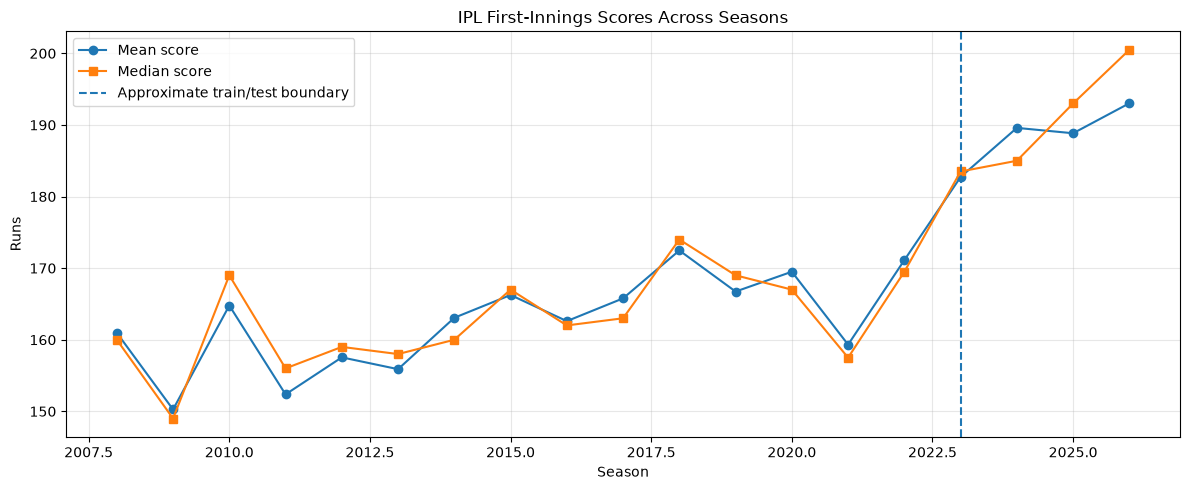

In [28]:
# Step 25: First-innings scoring trends by season

season_scores = (
    score_df.groupby("season")["first_innings_runs"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

print("FIRST-INNINGS SCORING BY SEASON")
display(season_scores)

plt.figure(figsize=(12, 5))
plt.plot(
    season_scores.index,
    season_scores["mean"],
    marker="o",
    label="Mean score"
)
plt.plot(
    season_scores.index,
    season_scores["median"],
    marker="s",
    label="Median score"
)
plt.axvline(2023, linestyle="--", label="Approximate train/test boundary")
plt.title("IPL First-Innings Scores Across Seasons")
plt.xlabel("Season")
plt.ylabel("Runs")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
# Step 26: Historical rolling baseline

score_df = score_df.sort_values("date").reset_index(drop=True).copy()

# Calculate season-level scoring averages
season_mean = score_df.groupby("season")["first_innings_runs"].mean()

# Each season's prediction uses the previous 3 available seasons
rolling_predictions = {}

for season in sorted(season_mean.index):
    previous_seasons = [
        s for s in sorted(season_mean.index) if s < season
    ][-3:]

    if previous_seasons:
        rolling_predictions[season] = season_mean.loc[previous_seasons].mean()

score_df["rolling_baseline_prediction"] = score_df["season"].map(
    rolling_predictions
)

# Evaluate only the same test matches used by our original baseline
test_mask = score_df.index >= split_index
rolling_test = score_df.loc[
    test_mask & score_df["rolling_baseline_prediction"].notna()
].copy()

rolling_test["error"] = (
    rolling_test["first_innings_runs"]
    - rolling_test["rolling_baseline_prediction"]
)

rolling_mae = rolling_test["error"].abs().mean()
rolling_rmse = np.sqrt((rolling_test["error"] ** 2).mean())

print("ROLLING HISTORICAL BASELINE")
print("=" * 40)
print("Test matches:", len(rolling_test))
print(f"MAE: {rolling_mae:.2f} runs")
print(f"RMSE: {rolling_rmse:.2f} runs")
print(f"Original baseline MAE: {mae:.2f} runs")
print(f"Original baseline RMSE: {rmse:.2f} runs")
print(
    "MAE improvement:",
    f"{mae - rolling_mae:.2f} runs"
)

ROLLING HISTORICAL BASELINE
Test matches: 249
MAE: 31.53 runs
RMSE: 40.09 runs
Original baseline MAE: 37.13 runs
Original baseline RMSE: 46.38 runs
MAE improvement: 5.60 runs


In [30]:
# Step 27: Create the pre-match modelling dataset

model_df = score_df.copy()

# Derive the opponent from the two teams in the match
def get_opponent(row):
    batting_team = row["first_batting_team"]

    if row["team_1"] == batting_team:
        return row["team_2"]
    elif row["team_2"] == batting_team:
        return row["team_1"]

    return np.nan

model_df["opponent"] = model_df.apply(get_opponent, axis=1)

feature_columns = [
    "season",
    "venue",
    "city",
    "first_batting_team",
    "opponent",
    "toss_winner",
    "toss_decision",
]

target_column = "first_innings_runs"

X = model_df[feature_columns].copy()
y = model_df[target_column].copy()

print("MODELLING DATASET")
print("=" * 40)
print("Rows:", len(model_df))
print("Features:", len(feature_columns))
print("Target:", target_column)
print("\nFeature missing values:")
display(X.isna().sum().to_frame("missing_count"))

print("\nSample features:")
display(X.head())

print("\nTarget sample:")
display(y.head())

MODELLING DATASET
Rows: 1243
Features: 7
Target: first_innings_runs

Feature missing values:


,missing_count
season,0
venue,0
city,51
first_batting_team,0
opponent,0
toss_winner,0
toss_decision,0



Sample features:


,season,venue,city,first_batting_team,opponent,toss_winner,toss_decision
0,2008,M Chinnaswamy Stadium,Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field
1,2008,"Punjab Cricket Association Stadium, Mohali",Chandigarh,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat
2,2008,Feroz Shah Kotla,Delhi,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat
3,2008,Eden Gardens,Kolkata,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat
4,2008,Wankhede Stadium,Mumbai,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat



Target sample:


0    222
1    240
2    129
3    110
4    165
Name: first_innings_runs, dtype: int64

In [31]:
# Step 28: Build a leakage-conscious Ridge Regression pipeline

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["season"]

categorical_features = [
    "venue",
    "city",
    "first_batting_team",
    "opponent",
    "toss_winner",
    "toss_decision",
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=10.0)),
])

# Match the original chronological split
X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

ridge_model.fit(X_train, y_train)
ridge_predictions = ridge_model.predict(X_test)

ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
ridge_r2 = r2_score(y_test, ridge_predictions)

print("RIDGE REGRESSION RESULTS")
print("=" * 40)
print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))
print(f"MAE: {ridge_mae:.2f} runs")
print(f"RMSE: {ridge_rmse:.2f} runs")
print(f"R²: {ridge_r2:.4f}")

print("\nBASELINE COMPARISON")
print(f"Fixed-average baseline MAE: {mae:.2f}")
print(f"Rolling-season baseline MAE: {rolling_mae:.2f}")
print(f"Ridge Regression MAE: {ridge_mae:.2f}")

RIDGE REGRESSION RESULTS
Training matches: 994
Testing matches: 249
MAE: 31.73 runs
RMSE: 40.59 runs
R²: -0.1338

BASELINE COMPARISON
Fixed-average baseline MAE: 37.13
Rolling-season baseline MAE: 31.53
Ridge Regression MAE: 31.73


ERROR SUMMARY
count    249.00
mean      12.72
std       38.63
min     -166.80
25%      -11.40
50%       14.39
75%       37.44
max      105.93
Name: error, dtype: float64

LARGEST PREDICTION ERRORS


,season,venue,first_batting_team,opponent,actual_runs,predicted_runs,error,absolute_error
1180,2026,"Eden Gardens, Kolkata",Kolkata Knight Riders,Punjab Kings,25,191.80,-166.80,166.80
1207,2026,"Arun Jaitley Stadium, Delhi",Delhi Capitals,Royal Challengers Bengaluru,75,182.64,-107.64,107.64
1096,2025,"Rajiv Gandhi International Stadium, Uppal, Hyd...",Sunrisers Hyderabad,Rajasthan Royals,286,180.07,105.93,105.93
1039,2024,Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...,Kolkata Knight Riders,Delhi Capitals,272,167.57,104.43,104.43
1031,2024,"Rajiv Gandhi International Stadium, Uppal, Hyd...",Sunrisers Hyderabad,Mumbai Indians,277,173.70,103.30,103.30
1053,2024,"M Chinnaswamy Stadium, Bengaluru",Sunrisers Hyderabad,Royal Challengers Bengaluru,287,184.81,102.19,102.19
1162,2025,"Arun Jaitley Stadium, Delhi",Sunrisers Hyderabad,Kolkata Knight Riders,278,176.17,101.83,101.83
1128,2025,"M Chinnaswamy Stadium, Bengaluru",Royal Challengers Bengaluru,Punjab Kings,95,186.27,-91.27,91.27
1235,2026,"Rajiv Gandhi International Stadium, Uppal, Hyd...",Sunrisers Hyderabad,Royal Challengers Bengaluru,255,170.83,84.17,84.17
1055,2024,"Narendra Modi Stadium, Ahmedabad",Gujarat Titans,Delhi Capitals,89,172.94,-83.94,83.94


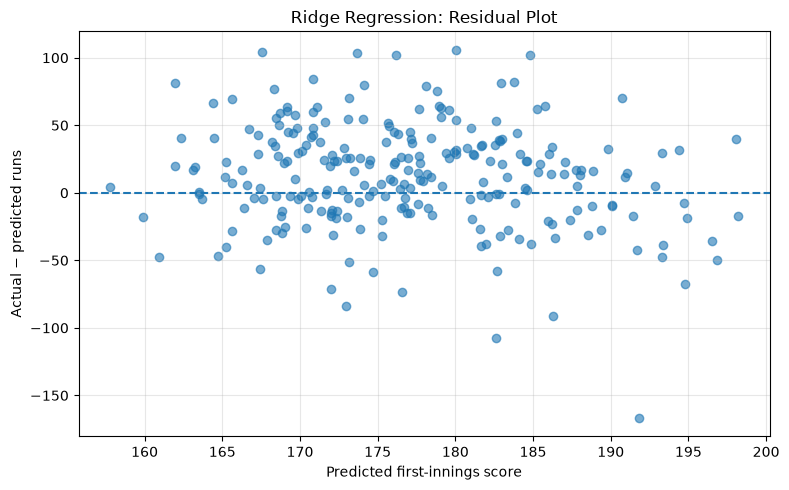

In [32]:
# Step 29: Analyze Ridge Regression prediction errors

error_analysis = X_test.copy()
error_analysis["actual_runs"] = y_test.to_numpy()
error_analysis["predicted_runs"] = ridge_predictions
error_analysis["error"] = (
    error_analysis["actual_runs"] - error_analysis["predicted_runs"]
)
error_analysis["absolute_error"] = error_analysis["error"].abs()

print("ERROR SUMMARY")
print("=" * 40)
print(error_analysis["error"].describe().round(2))

print("\nLARGEST PREDICTION ERRORS")
display(
    error_analysis.sort_values("absolute_error", ascending=False)[
        [
            "season",
            "venue",
            "first_batting_team",
            "opponent",
            "actual_runs",
            "predicted_runs",
            "error",
            "absolute_error",
        ]
    ].head(10).round(2)
)

plt.figure(figsize=(8, 5))
plt.scatter(error_analysis["predicted_runs"], error_analysis["error"], alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted first-innings score")
plt.ylabel("Actual − predicted runs")
plt.title("Ridge Regression: Residual Plot")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Step 30: Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=4,
        max_features=0.8,
        random_state=42,
        n_jobs=-1,
    )),
])

rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

results_df = pd.DataFrame([
    {
        "model": "Fixed historical average",
        "MAE": mae,
        "RMSE": rmse,
    },
    {
        "model": "Rolling seasonal average",
        "MAE": rolling_mae,
        "RMSE": rolling_rmse,
    },
    {
        "model": "Ridge Regression",
        "MAE": ridge_mae,
        "RMSE": ridge_rmse,
    },
    {
        "model": "Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
    },
])

print("RANDOM FOREST RESULTS")
print("=" * 40)
print(f"MAE: {rf_mae:.2f} runs")
print(f"RMSE: {rf_rmse:.2f} runs")
print(f"R²: {rf_r2:.4f}")

print("\nMODEL COMPARISON")
display(results_df.sort_values("MAE").round(2).reset_index(drop=True))

RANDOM FOREST RESULTS
MAE: 31.20 runs
RMSE: 39.77 runs
R²: -0.0882

MODEL COMPARISON


,model,MAE,RMSE
0,Random Forest,31.20,39.77
1,Rolling seasonal average,31.53,40.09
2,Ridge Regression,31.73,40.59
3,Fixed historical average,37.13,46.38


In [34]:
# Step 31: Historical batting form — strictly prior matches

form_df = score_df[
    ["match_id", "date", "first_batting_team", "first_innings_runs"]
].copy()

# Establish a deterministic chronological order
form_df = form_df.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

form_df["team_last5_first_innings_avg"] = (
    form_df.groupby("first_batting_team")["first_innings_runs"]
    .transform(
        lambda scores: scores.shift(1).rolling(
            window=5,
            min_periods=1
        ).mean()
    )
)

print("HISTORICAL FORM FEATURE")
print("=" * 40)
print("Matches:", len(form_df))
print(
    "Missing form values:",
    form_df["team_last5_first_innings_avg"].isna().sum()
)

display(
    form_df[
        [
            "date",
            "first_batting_team",
            "first_innings_runs",
            "team_last5_first_innings_avg",
        ]
    ].head(15).round(2)
)

HISTORICAL FORM FEATURE
Matches: 1243
Missing form values: 19


C:\Users\amitb\AppData\Local\Temp\ipykernel_34352\2292755140.py:38: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(2)


,date,first_batting_team,first_innings_runs,team_last5_first_innings_avg
0,2008-04-18,Kolkata Knight Riders,222,NaN
1,2008-04-19,Chennai Super Kings,240,NaN
2,2008-04-19,Rajasthan Royals,129,NaN
3,2008-04-20,Mumbai Indians,165,NaN
4,2008-04-20,Deccan Chargers,110,NaN
5,2008-04-21,Kings XI Punjab,166,NaN
6,2008-04-22,Deccan Chargers,142,110.0
7,2008-04-23,Chennai Super Kings,208,240.0
8,2008-04-24,Deccan Chargers,214,126.0
9,2008-04-25,Kings XI Punjab,182,166.0


In [35]:
# Step 32: Add historical form and retrain Random Forest

form_lookup = form_df[
    ["match_id", "team_last5_first_innings_avg"]
].copy()

model_df_form = model_df.merge(
    form_lookup,
    on="match_id",
    how="left",
    validate="one_to_one"
)

new_feature_columns = feature_columns + [
    "team_last5_first_innings_avg"
]

X_form = model_df_form[new_feature_columns].copy()
y_form = model_df_form[target_column].copy()

# Preserve the same chronological split for a fair comparison
X_train_form = X_form.iloc[:split_index].copy()
X_test_form = X_form.iloc[split_index:].copy()
y_train_form = y_form.iloc[:split_index].copy()
y_test_form = y_form.iloc[split_index:].copy()

# Reuse the preprocessing design, adding numeric handling for team form
form_preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]),
        ["season", "team_last5_first_innings_avg"],
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features,
    ),
])

rf_form_model = Pipeline([
    ("preprocessor", form_preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=4,
        max_features=0.8,
        random_state=42,
        n_jobs=-1,
    )),
])

rf_form_model.fit(X_train_form, y_train_form)
rf_form_predictions = rf_form_model.predict(X_test_form)

rf_form_mae = mean_absolute_error(y_test_form, rf_form_predictions)
rf_form_rmse = np.sqrt(
    mean_squared_error(y_test_form, rf_form_predictions)
)
rf_form_r2 = r2_score(y_test_form, rf_form_predictions)

print("RANDOM FOREST WITH TEAM FORM")
print("=" * 40)
print("Training matches:", len(X_train_form))
print("Testing matches:", len(X_test_form))
print("Missing form values before imputation:", X_form[
    "team_last5_first_innings_avg"
].isna().sum())
print(f"MAE: {rf_form_mae:.2f} runs")
print(f"RMSE: {rf_form_rmse:.2f} runs")
print(f"R²: {rf_form_r2:.4f}")

print("\nCOMPARISON")
display(pd.DataFrame([
    {
        "model": "Random Forest — original features",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "R2": rf_r2,
    },
    {
        "model": "Random Forest — plus team form",
        "MAE": rf_form_mae,
        "RMSE": rf_form_rmse,
        "R2": rf_form_r2,
    },
]).round(3))

RANDOM FOREST WITH TEAM FORM
Training matches: 994
Testing matches: 249
Missing form values before imputation: 19
MAE: 32.69 runs
RMSE: 41.74 runs
R²: -0.1987

COMPARISON


,model,MAE,RMSE,R2
0,Random Forest — original features,31.202,39.769,-0.088
1,Random Forest — plus team form,32.694,41.739,-0.199


In [36]:
# Step 33: Recency-weighted baseline

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the same chronological training and test target values
train_scores = y_train.to_numpy()
test_scores = y_test.to_numpy()

# Exponentially weighted average: recent training matches get more weight
decay_factors = [0.99, 0.995, 0.998]

weighted_results = []

for decay in decay_factors:
    weights = decay ** np.arange(len(train_scores) - 1, -1, -1)
    weights = weights / weights.sum()

    prediction = np.average(train_scores, weights=weights)
    predictions = np.full(len(test_scores), prediction)

    weighted_results.append({
        "decay": decay,
        "baseline_prediction": prediction,
        "MAE": mean_absolute_error(test_scores, predictions),
        "RMSE": np.sqrt(mean_squared_error(test_scores, predictions)),
        "R2": r2_score(test_scores, predictions),
    })

weighted_results_df = pd.DataFrame(weighted_results)

print("RECENCY-WEIGHTED BASELINES")
print("=" * 40)
display(weighted_results_df.round(3))

print("\nCURRENT BENCHMARKS")
display(pd.DataFrame([
    {"model": "Rolling seasonal average", "MAE": rolling_mae, "RMSE": rolling_rmse},
    {"model": "Random Forest", "MAE": rf_mae, "RMSE": rf_rmse},
]).round(3))

RECENCY-WEIGHTED BASELINES


,decay,baseline_prediction,MAE,RMSE,R2
0,0.990,172.498,33.131,41.820,-0.203
1,0.995,169.495,34.281,43.141,-0.281
2,0.998,166.269,35.659,44.741,-0.377



CURRENT BENCHMARKS


,model,MAE,RMSE
0,Rolling seasonal average,31.532,40.089
1,Random Forest,31.202,39.769


In [37]:
print("RECENCY-WEIGHTED BASELINE RESULTS")
display(weighted_results_df.round(3))

RECENCY-WEIGHTED BASELINE RESULTS


,decay,baseline_prediction,MAE,RMSE,R2
0,0.990,172.498,33.131,41.820,-0.203
1,0.995,169.495,34.281,43.141,-0.281
2,0.998,166.269,35.659,44.741,-0.377


In [38]:
# Step 34: Rolling league-wide scoring environment

trend_df = score_df[
    ["match_id", "date", "first_innings_runs"]
].copy()

trend_df = trend_df.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

trend_df["league_last30_avg_score"] = (
    trend_df["first_innings_runs"]
    .shift(1)
    .rolling(window=30, min_periods=10)
    .mean()
)

print("LEAGUE SCORING TREND FEATURE")
print("=" * 40)
print("Matches:", len(trend_df))
print(
    "Missing values:",
    trend_df["league_last30_avg_score"].isna().sum()
)

display(
    trend_df[
        ["date", "first_innings_runs", "league_last30_avg_score"]
    ].iloc[25:45].round(2)
)

LEAGUE SCORING TREND FEATURE
Matches: 1243
Missing values: 10


C:\Users\amitb\AppData\Local\Temp\ipykernel_34352\4232501766.py:29: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].iloc[25:45].round(2)


,date,first_innings_runs,league_last30_avg_score
25,2008-05-06,144,165.52
26,2008-05-07,103,164.69
27,2008-05-08,187,162.41
28,2008-05-08,129,163.29
29,2008-05-09,140,162.10
30,2008-05-10,181,161.37
31,2008-05-11,204,160.00
32,2008-05-11,156,158.80
33,2008-05-12,143,159.70
34,2008-05-13,133,158.97


In [39]:
# Step 35: Random Forest with league scoring trend

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Attach the trend feature to the match-level dataset
trend_lookup = trend_df[
    ["match_id", "league_last30_avg_score"]
].copy()

model_df_trend = model_df.merge(
    trend_lookup,
    on="match_id",
    how="left",
    validate="one_to_one"
)

trend_features = feature_columns + ["league_last30_avg_score"]

X_trend = model_df_trend[trend_features].copy()
y_trend = model_df_trend[target_column].copy()

numeric_trend_features = [
    "season",
    "league_last30_avg_score"
]

categorical_features = [
    "venue",
    "city",
    "first_batting_team",
    "opponent",
    "toss_winner",
    "toss_decision"
]

trend_preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_trend_features
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    )
])

rf_trend_model = Pipeline([
    ("preprocessor", trend_preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=4,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

X_train_trend = X_trend.iloc[:split_index].copy()
X_test_trend = X_trend.iloc[split_index:].copy()
y_train_trend = y_trend.iloc[:split_index].copy()
y_test_trend = y_trend.iloc[split_index:].copy()

rf_trend_model.fit(X_train_trend, y_train_trend)

trend_predictions = rf_trend_model.predict(X_test_trend)

trend_mae = mean_absolute_error(y_test_trend, trend_predictions)
trend_rmse = np.sqrt(
    mean_squared_error(y_test_trend, trend_predictions)
)
trend_r2 = r2_score(y_test_trend, trend_predictions)

print("RANDOM FOREST + LEAGUE TREND")
print("=" * 40)
print("MAE:", round(trend_mae, 3))
print("RMSE:", round(trend_rmse, 3))
print("R²:", round(trend_r2, 3))

print("\nCOMPARISON")
display(pd.DataFrame([
    {
        "model": "Fixed mean baseline",
        "MAE": mae,
        "RMSE": rmse
    },
    {
        "model": "Rolling seasonal baseline",
        "MAE": rolling_mae,
        "RMSE": rolling_rmse
    },
    {
        "model": "Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse
    },
    {
        "model": "Random Forest + league trend",
        "MAE": trend_mae,
        "RMSE": trend_rmse
    }
]).sort_values("MAE").round(3))

RANDOM FOREST + LEAGUE TREND
MAE: 32.285
RMSE: 41.093
R²: -0.162

COMPARISON


,model,MAE,RMSE
2,Random Forest,31.202,39.769
1,Rolling seasonal baseline,31.532,40.089
3,Random Forest + league trend,32.285,41.093
0,Fixed mean baseline,37.130,46.376


In [40]:
# Step 37: Random Forest feature importance

fitted_preprocessor = rf_model.named_steps["preprocessor"]
fitted_forest = rf_model.named_steps["regressor"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_forest.feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

print("TOP 20 MODEL FEATURES")
display(importance_df.head(20).round(4))

# Aggregate one-hot encoded categories back to their original columns
def get_original_feature(feature_name):
    clean_name = feature_name.split("__", 1)[-1]

    for column in categorical_features:
        if clean_name == column or clean_name.startswith(column + "_"):
            return column

    return clean_name

importance_df["feature_group"] = importance_df["feature"].apply(
    get_original_feature
)

group_importance = (
    importance_df.groupby("feature_group", as_index=False)["importance"]
    .sum()
    .sort_values("importance", ascending=False)
)

print("\nIMPORTANCE BY FEATURE GROUP")
display(group_importance.round(4))

TOP 20 MODEL FEATURES


,feature,importance
0,numeric__season,0.2684
81,categorical__city_Mumbai,0.0308
107,categorical__first_batting_team_Royal Challeng...,0.0247
146,categorical__toss_decision_field,0.0227
91,categorical__first_batting_team_Chennai Super ...,0.0224
145,categorical__toss_decision_bat,0.0215
89,categorical__city_Sharjah,0.0198
115,categorical__opponent_Kings XI Punjab,0.0180
99,categorical__first_batting_team_Kolkata Knight...,0.0177
144,categorical__toss_winner_Sunrisers Hyderabad,0.0169



IMPORTANCE BY FEATURE GROUP


,feature_group,importance
3,season,0.2684
1,first_batting_team,0.1538
0,city,0.1502
6,venue,0.1339
2,opponent,0.1291
5,toss_winner,0.1204
4,toss_decision,0.0442


In [41]:
# Step 38: Test how predictive season alone is

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_season = score_df[["season"]].copy()
y_season = score_df["first_innings_runs"].copy()

X_train_season = X_season.iloc[:split_index]
X_test_season = X_season.iloc[split_index:]
y_train_season = y_season.iloc[:split_index]
y_test_season = y_season.iloc[split_index:]

season_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=4,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

season_model.fit(X_train_season, y_train_season)
season_predictions = season_model.predict(X_test_season)

season_mae = mean_absolute_error(y_test_season, season_predictions)
season_rmse = np.sqrt(mean_squared_error(y_test_season, season_predictions))
season_r2 = r2_score(y_test_season, season_predictions)

print("SEASON-ONLY RANDOM FOREST")
print("=" * 35)
print("MAE:", round(season_mae, 3))
print("RMSE:", round(season_rmse, 3))
print("R²:", round(season_r2, 3))

print("\nMODEL COMPARISON")
display(pd.DataFrame([
    {"model": "Fixed mean baseline", "MAE": mae, "RMSE": rmse},
    {"model": "Rolling seasonal baseline", "MAE": rolling_mae, "RMSE": rolling_rmse},
    {"model": "Season only", "MAE": season_mae, "RMSE": season_rmse},
    {"model": "Full Random Forest", "MAE": rf_mae, "RMSE": rf_rmse},
]).sort_values("MAE").round(3))

SEASON-ONLY RANDOM FOREST
MAE: 30.572
RMSE: 38.846
R²: -0.038

MODEL COMPARISON


,model,MAE,RMSE
2,Season only,30.572,38.846
3,Full Random Forest,31.202,39.769
1,Rolling seasonal baseline,31.532,40.089
0,Fixed mean baseline,37.130,46.376


In [42]:
# Step 39: Linear regression using season only

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

linear_trend_model = LinearRegression()

linear_trend_model.fit(X_train_season, y_train_season)

linear_trend_predictions = linear_trend_model.predict(X_test_season)

linear_trend_mae = mean_absolute_error(
    y_test_season, linear_trend_predictions
)
linear_trend_rmse = np.sqrt(
    mean_squared_error(y_test_season, linear_trend_predictions)
)
linear_trend_r2 = r2_score(
    y_test_season, linear_trend_predictions
)

print("LINEAR SEASON TREND")
print("=" * 35)
print("MAE:", round(linear_trend_mae, 3))
print("RMSE:", round(linear_trend_rmse, 3))
print("R²:", round(linear_trend_r2, 3))
print("Trend per year:", round(linear_trend_model.coef_[0], 3), "runs")

print("\nMODEL COMPARISON")
display(pd.DataFrame([
    {"model": "Fixed mean baseline", "MAE": mae, "RMSE": rmse},
    {"model": "Rolling seasonal baseline", "MAE": rolling_mae, "RMSE": rolling_rmse},
    {"model": "Season-only Random Forest", "MAE": season_mae, "RMSE": season_rmse},
    {"model": "Linear season trend", "MAE": linear_trend_mae, "RMSE": linear_trend_rmse},
    {"model": "Full Random Forest", "MAE": rf_mae, "RMSE": rf_rmse},
]).sort_values("MAE").round(3))

LINEAR SEASON TREND
MAE: 32.422
RMSE: 40.966
R²: -0.155
Trend per year: 1.197 runs

MODEL COMPARISON


,model,MAE,RMSE
2,Season-only Random Forest,30.572,38.846
4,Full Random Forest,31.202,39.769
1,Rolling seasonal baseline,31.532,40.089
3,Linear season trend,32.422,40.966
0,Fixed mean baseline,37.130,46.376


In [43]:
# Step 40: Error analysis for the best season-only model

error_df = pd.DataFrame({
    "date": score_df.iloc[split_index:]["date"].to_numpy(),
    "season": y_test_season.index.map(
        score_df["season"].to_dict()
    ).to_numpy(),
    "actual": y_test_season.to_numpy(),
    "predicted": season_predictions
})

error_df["error"] = error_df["actual"] - error_df["predicted"]
error_df["absolute_error"] = error_df["error"].abs()

print("OVERALL ERROR SUMMARY")
display(
    error_df[["actual", "predicted", "error", "absolute_error"]]
    .describe()
    .round(2)
)

print("\nLARGEST PREDICTION ERRORS")
display(
    error_df.sort_values("absolute_error", ascending=False)
    [["date", "season", "actual", "predicted", "error"]]
    .head(15)
    .round(2)
)

print("\nERROR BY ACTUAL SCORE RANGE")
error_df["score_range"] = pd.cut(
    error_df["actual"],
    bins=[0, 120, 160, 200, 240, float("inf")],
    labels=["Under 120", "120–160", "160–200", "200–240", "240+"]
)

display(
    error_df.groupby("score_range", observed=False)
    .agg(
        matches=("actual", "size"),
        mean_actual=("actual", "mean"),
        mean_predicted=("predicted", "mean"),
        MAE=("absolute_error", "mean"),
        mean_error=("error", "mean")
    )
    .round(2)
)

OVERALL ERROR SUMMARY


,actual,predicted,error,absolute_error
count,249.00,249.00,249.00,249.00
mean,189.69,182.23,7.45,30.57
std,38.20,0.00,38.20,24.01
min,25.00,182.23,-157.23,0.23
25%,165.00,182.23,-17.23,13.77
50%,192.00,182.23,9.77,25.23
75%,214.00,182.23,31.77,40.77
max,287.00,182.23,104.77,157.23



LARGEST PREDICTION ERRORS


C:\Users\amitb\AppData\Local\Temp\ipykernel_34352\2045271319.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,date,season,actual,predicted,error
186,2026-04-06,2026,25,182.23,-157.23
213,2026-04-27,2026,75,182.23,-107.23
59,2024-04-15,2024,287,182.23,104.77
102,2025-03-23,2025,286,182.23,103.77
168,2025-05-25,2025,278,182.23,95.77
37,2024-03-27,2024,277,182.23,94.77
61,2024-04-17,2024,89,182.23,-93.23
45,2024-04-03,2024,272,182.23,89.77
134,2025-04-18,2025,95,182.23,-87.23
64,2024-04-20,2024,266,182.23,83.77



ERROR BY ACTUAL SCORE RANGE


,matches,mean_actual,mean_predicted,MAE,mean_error
score_range,,,,,
Under 120,10,94.60,182.23,87.63,-87.63
120–160,40,147.35,182.23,34.88,-34.88
160–200,97,180.27,182.23,10.54,-1.96
200–240,82,216.35,182.23,34.12,34.12
240+,20,258.25,182.23,76.02,76.02


In [44]:
# Step 41: Check prediction variability

prediction_diagnostics = pd.DataFrame([
    {
        "model": "Season-only Random Forest",
        "prediction_mean": season_predictions.mean(),
        "prediction_std": season_predictions.std(),
        "unique_rounded_predictions": len(
            np.unique(np.round(season_predictions, 2))
        ),
    },
    {
        "model": "Full Random Forest",
        "prediction_mean": rf_predictions.mean(),
        "prediction_std": rf_predictions.std(),
        "unique_rounded_predictions": len(
            np.unique(np.round(rf_predictions, 2))
        ),
    },
    {
        "model": "Linear season trend",
        "prediction_mean": linear_trend_predictions.mean(),
        "prediction_std": linear_trend_predictions.std(),
        "unique_rounded_predictions": len(
            np.unique(np.round(linear_trend_predictions, 2))
        ),
    },
])

print("PREDICTION VARIABILITY")
display(prediction_diagnostics.round(3))

PREDICTION VARIABILITY


,model,prediction_mean,prediction_std,unique_rounded_predictions
0,Season-only Random Forest,182.232,0.000,1
1,Full Random Forest,179.933,7.516,181
2,Linear season trend,174.547,1.204,4


In [45]:
# Step 42: Rolling 30-match scoring baseline

rolling30_df = score_df[
    ["match_id", "date", "first_innings_runs"]
].copy()

rolling30_df = rolling30_df.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

rolling30_df["rolling30_prediction"] = (
    rolling30_df["first_innings_runs"]
    .shift(1)
    .rolling(window=30, min_periods=10)
    .mean()
)

rolling30_test = rolling30_df.iloc[split_index:].copy()
rolling30_test = rolling30_test.dropna(
    subset=["rolling30_prediction"]
)

rolling30_mae = mean_absolute_error(
    rolling30_test["first_innings_runs"],
    rolling30_test["rolling30_prediction"]
)

rolling30_rmse = np.sqrt(
    mean_squared_error(
        rolling30_test["first_innings_runs"],
        rolling30_test["rolling30_prediction"]
    )
)

rolling30_r2 = r2_score(
    rolling30_test["first_innings_runs"],
    rolling30_test["rolling30_prediction"]
)

print("ROLLING 30-MATCH BASELINE")
print("=" * 35)
print("Evaluated matches:", len(rolling30_test))
print("MAE:", round(rolling30_mae, 3))
print("RMSE:", round(rolling30_rmse, 3))
print("R²:", round(rolling30_r2, 3))

print("\nPREDICTION VARIABILITY")
print(
    "Prediction standard deviation:",
    round(rolling30_test["rolling30_prediction"].std(), 3)
)

display(
    rolling30_test[
        ["date", "first_innings_runs", "rolling30_prediction"]
    ].head(10).round(2)
)

ROLLING 30-MATCH BASELINE
Evaluated matches: 249
MAE: 30.283
RMSE: 38.777
R²: -0.035

PREDICTION VARIABILITY
Prediction standard deviation: 5.807


C:\Users\amitb\AppData\Local\Temp\ipykernel_34352\1500514650.py:56: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,date,first_innings_runs,rolling30_prediction
994,2023-05-03,125,182.30
995,2023-05-03,214,179.40
996,2023-05-04,171,180.80
997,2023-05-05,118,180.67
998,2023-05-06,139,179.50
999,2023-05-06,181,176.53
1000,2023-05-07,227,176.77
1001,2023-05-07,214,179.03
1002,2023-05-08,179,180.00
1003,2023-05-09,199,180.07


In [46]:
# Step 43: Leakage-safer rolling baseline by date

daily_scores = (
    score_df.groupby("date", as_index=False)
    .agg(
        daily_total=("first_innings_runs", "sum"),
        daily_matches=("first_innings_runs", "count")
    )
    .sort_values("date")
    .reset_index(drop=True)
)

# Average score across all matches on each date
daily_scores["daily_average"] = (
    daily_scores["daily_total"] / daily_scores["daily_matches"]
)

# Shift by one date before rolling, so today's results are excluded
daily_scores["prior_dates_30_avg"] = (
    daily_scores["daily_average"]
    .shift(1)
    .rolling(window=30, min_periods=10)
    .mean()
)

# Attach the historical estimate to each match by date
safe_rolling_df = score_df[
    ["match_id", "date", "first_innings_runs"]
].merge(
    daily_scores[["date", "prior_dates_30_avg"]],
    on="date",
    how="left",
    validate="many_to_one"
)

safe_rolling_df = safe_rolling_df.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

safe_test = safe_rolling_df.iloc[split_index:].dropna(
    subset=["prior_dates_30_avg"]
)

safe_mae = mean_absolute_error(
    safe_test["first_innings_runs"],
    safe_test["prior_dates_30_avg"]
)

safe_rmse = np.sqrt(
    mean_squared_error(
        safe_test["first_innings_runs"],
        safe_test["prior_dates_30_avg"]
    )
)

safe_r2 = r2_score(
    safe_test["first_innings_runs"],
    safe_test["prior_dates_30_avg"]
)

print("DATE-SAFE ROLLING BASELINE")
print("=" * 35)
print("Evaluated matches:", len(safe_test))
print("MAE:", round(safe_mae, 3))
print("RMSE:", round(safe_rmse, 3))
print("R²:", round(safe_r2, 3))

display(
    safe_test[
        ["date", "first_innings_runs", "prior_dates_30_avg"]
    ].head(10).round(2)
)

DATE-SAFE ROLLING BASELINE
Evaluated matches: 249
MAE: 30.322
RMSE: 38.734
R²: -0.032


C:\Users\amitb\AppData\Local\Temp\ipykernel_34352\905201659.py:71: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,date,first_innings_runs,prior_dates_30_avg
994,2023-05-03,125,181.43
995,2023-05-03,214,181.43
996,2023-05-04,171,179.85
997,2023-05-05,118,180.15
998,2023-05-06,139,177.52
999,2023-05-06,181,177.52
1000,2023-05-07,227,176.05
1001,2023-05-07,214,176.05
1002,2023-05-08,179,179.37
1003,2023-05-09,199,179.40


In [47]:
# Step 44: Consolidated model benchmark

benchmark_df = pd.DataFrame([
    {
        "model": "Fixed mean baseline",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    },
    {
        "model": "Rolling seasonal baseline",
        "MAE": rolling_mae,
        "RMSE": rolling_rmse,
        "R2": np.nan
    },
    {
        "model": "Rolling 30-match baseline",
        "MAE": rolling30_mae,
        "RMSE": rolling30_rmse,
        "R2": rolling30_r2
    },
    {
        "model": "Date-safe rolling baseline",
        "MAE": safe_mae,
        "RMSE": safe_rmse,
        "R2": safe_r2
    },
    {
        "model": "Season-only Random Forest",
        "MAE": season_mae,
        "RMSE": season_rmse,
        "R2": season_r2
    },
    {
        "model": "Full Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "R2": rf_r2
    },
    {
        "model": "Random Forest + league trend",
        "MAE": trend_mae,
        "RMSE": trend_rmse,
        "R2": trend_r2
    },
    {
        "model": "Linear season trend",
        "MAE": linear_trend_mae,
        "RMSE": linear_trend_rmse,
        "R2": linear_trend_r2
    }
]).sort_values("MAE").reset_index(drop=True)

display(benchmark_df.round(3))

,model,MAE,RMSE,R2
0,Rolling 30-match baseline,30.283,38.777,-0.035
1,Date-safe rolling baseline,30.322,38.734,-0.032
2,Season-only Random Forest,30.572,38.846,-0.038
3,Full Random Forest,31.202,39.769,-0.088
4,Rolling seasonal baseline,31.532,40.089,NaN
5,Random Forest + league trend,32.285,41.093,-0.162
6,Linear season trend,32.422,40.966,-0.155
7,Fixed mean baseline,37.130,46.376,-0.480


In [48]:
# Step 45: Historical team and venue scoring features

history_df = score_df[
    [
        "match_id",
        "date",
        "first_batting_team",
        "venue",
        "first_innings_runs"
    ]
].copy()

history_df = history_df.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

# Team scoring history: previous matches on earlier dates only
team_daily = (
    history_df.groupby(
        ["date", "first_batting_team"],
        as_index=False
    )
    .agg(
        team_daily_runs=("first_innings_runs", "sum"),
        team_daily_matches=("first_innings_runs", "count")
    )
)

team_daily["team_daily_avg"] = (
    team_daily["team_daily_runs"] / team_daily["team_daily_matches"]
)

team_daily = team_daily.sort_values(
    ["first_batting_team", "date"]
).reset_index(drop=True)

team_daily["team_prior_avg"] = (
    team_daily.groupby("first_batting_team")["team_daily_avg"]
    .transform(lambda s: s.shift(1).rolling(5, min_periods=2).mean())
)

# Venue scoring history: previous dates at the same venue
venue_daily = (
    history_df.groupby(["date", "venue"], as_index=False)
    .agg(
        venue_daily_runs=("first_innings_runs", "sum"),
        venue_daily_matches=("first_innings_runs", "count")
    )
)

venue_daily["venue_daily_avg"] = (
    venue_daily["venue_daily_runs"] / venue_daily["venue_daily_matches"]
)

venue_daily = venue_daily.sort_values(
    ["venue", "date"]
).reset_index(drop=True)

venue_daily["venue_prior_avg"] = (
    venue_daily.groupby("venue")["venue_daily_avg"]
    .transform(lambda s: s.shift(1).rolling(10, min_periods=3).mean())
)

# Attach history features back to matches
history_df = history_df.merge(
    team_daily[["date", "first_batting_team", "team_prior_avg"]],
    on=["date", "first_batting_team"],
    how="left",
    validate="many_to_one"
)

history_df = history_df.merge(
    venue_daily[["date", "venue", "venue_prior_avg"]],
    on=["date", "venue"],
    how="left",
    validate="many_to_one"
)

print("HISTORICAL FEATURE AUDIT")
print("=" * 35)
print("Matches:", len(history_df))
print("Missing team history:", history_df["team_prior_avg"].isna().sum())
print("Missing venue history:", history_df["venue_prior_avg"].isna().sum())

display(
    history_df[
        [
            "date",
            "first_batting_team",
            "venue",
            "first_innings_runs",
            "team_prior_avg",
            "venue_prior_avg"
        ]
    ].tail(15).round(2)
)

HISTORICAL FEATURE AUDIT
Matches: 1243
Missing team history: 38
Missing venue history: 184


C:\Users\amitb\AppData\Local\Temp\ipykernel_34352\648850851.py:95: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(15).round(2)


,date,first_batting_team,venue,first_innings_runs,team_prior_avg,venue_prior_avg
1228,2026-05-16,Kolkata Knight Riders,"Eden Gardens, Kolkata",247,146.6,180.90
1229,2026-05-17,Royal Challengers Bengaluru,"Himachal Pradesh Cricket Association Stadium, ...",222,204.2,197.00
1230,2026-05-17,Rajasthan Royals,"Arun Jaitley Stadium, Delhi",193,183.4,187.60
1231,2026-05-18,Chennai Super Kings,"MA Chidambaram Stadium, Chepauk, Chennai",180,191.2,176.30
1232,2026-05-19,Lucknow Super Giants,"Sawai Mansingh Stadium, Jaipur",220,190.0,207.00
1233,2026-05-20,Mumbai Indians,"Eden Gardens, Kolkata",147,192.4,185.60
1234,2026-05-21,Gujarat Titans,"Narendra Modi Stadium, Ahmedabad",229,194.8,193.30
1235,2026-05-22,Sunrisers Hyderabad,"Rajiv Gandhi International Stadium, Uppal, Hyd...",255,210.4,188.10
1236,2026-05-23,Lucknow Super Giants,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...,196,201.2,183.70
1237,2026-05-24,Rajasthan Royals,"Wankhede Stadium, Mumbai",205,192.0,205.90


In [49]:
# Step 46: Random Forest with team and venue history

history_lookup = history_df[
    ["match_id", "team_prior_avg", "venue_prior_avg"]
].copy()

model_df_history = model_df.merge(
    history_lookup,
    on="match_id",
    how="left",
    validate="one_to_one"
)

history_features = feature_columns + [
    "team_prior_avg",
    "venue_prior_avg"
]

X_history = model_df_history[history_features].copy()
y_history = model_df_history[target_column].copy()

numeric_history_features = [
    "season",
    "team_prior_avg",
    "venue_prior_avg"
]

categorical_history_features = [
    "venue",
    "city",
    "first_batting_team",
    "opponent",
    "toss_winner",
    "toss_decision"
]

history_preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_history_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_history_features
    )
])

rf_history_model = Pipeline([
    ("preprocessor", history_preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=4,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

X_train_history = X_history.iloc[:split_index].copy()
X_test_history = X_history.iloc[split_index:].copy()
y_train_history = y_history.iloc[:split_index].copy()
y_test_history = y_history.iloc[split_index:].copy()

rf_history_model.fit(X_train_history, y_train_history)

history_predictions = rf_history_model.predict(X_test_history)

history_mae = mean_absolute_error(
    y_test_history, history_predictions
)
history_rmse = np.sqrt(
    mean_squared_error(y_test_history, history_predictions)
)
history_r2 = r2_score(
    y_test_history, history_predictions
)

print("RANDOM FOREST + HISTORICAL TEAM/VENUE FEATURES")
print("=" * 50)
print("MAE:", round(history_mae, 3))
print("RMSE:", round(history_rmse, 3))
print("R²:", round(history_r2, 3))

print("\nPREDICTION VARIABILITY")
print("Prediction standard deviation:", round(history_predictions.std(), 3))
print(
    "Unique rounded predictions:",
    len(np.unique(np.round(history_predictions, 2)))
)

print("\nBENCHMARK COMPARISON")
display(pd.DataFrame([
    {
        "model": "Date-safe rolling baseline",
        "MAE": safe_mae,
        "RMSE": safe_rmse
    },
    {
        "model": "Season-only Random Forest",
        "MAE": season_mae,
        "RMSE": season_rmse
    },
    {
        "model": "Full Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse
    },
    {
        "model": "RF + team/venue history",
        "MAE": history_mae,
        "RMSE": history_rmse
    }
]).sort_values("MAE").round(3))

RANDOM FOREST + HISTORICAL TEAM/VENUE FEATURES
MAE: 32.031
RMSE: 40.558
R²: -0.132

PREDICTION VARIABILITY
Prediction standard deviation: 7.121
Unique rounded predictions: 238

BENCHMARK COMPARISON


,model,MAE,RMSE
0,Date-safe rolling baseline,30.322,38.734
1,Season-only Random Forest,30.572,38.846
2,Full Random Forest,31.202,39.769
3,RF + team/venue history,32.031,40.558


In [50]:
# Step 47: Gradient boosting with season and historical scoring context

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_features = ["season"]

X_numeric = score_df[numeric_features].copy()
y_numeric = score_df["first_innings_runs"].copy()

X_train_num = X_numeric.iloc[:split_index].copy()
X_test_num = X_numeric.iloc[split_index:].copy()
y_train_num = y_numeric.iloc[:split_index].copy()
y_test_num = y_numeric.iloc[split_index:].copy()

hgb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=5.0,
        random_state=42
    ))
])

hgb_model.fit(X_train_num, y_train_num)

hgb_predictions = hgb_model.predict(X_test_num)

hgb_mae = mean_absolute_error(y_test_num, hgb_predictions)
hgb_rmse = np.sqrt(mean_squared_error(y_test_num, hgb_predictions))
hgb_r2 = r2_score(y_test_num, hgb_predictions)

print("HIST GRADIENT BOOSTING — SEASON ONLY")
print("=" * 45)
print("MAE:", round(hgb_mae, 3))
print("RMSE:", round(hgb_rmse, 3))
print("R²:", round(hgb_r2, 3))
print("Prediction standard deviation:", round(hgb_predictions.std(), 3))
print("Unique rounded predictions:", len(np.unique(np.round(hgb_predictions, 2))))

HIST GRADIENT BOOSTING — SEASON ONLY
MAE: 30.6
RMSE: 38.887
R²: -0.04
Prediction standard deviation: 0.0
Unique rounded predictions: 1


In [51]:
# Step 48: Audit the chronological train/test split

train_seasons = score_df.iloc[:split_index]["season"]
test_seasons = score_df.iloc[split_index:]["season"]

print("TRAINING PERIOD")
print("First date:", score_df.iloc[:split_index]["date"].min().date())
print("Last date: ", score_df.iloc[:split_index]["date"].max().date())
print("Seasons:", sorted(train_seasons.unique().tolist()))

print("\nTEST PERIOD")
print("First date:", score_df.iloc[split_index:]["date"].min().date())
print("Last date: ", score_df.iloc[split_index:]["date"].max().date())
print("Seasons:", sorted(test_seasons.unique().tolist()))

print("\nSEASONS PRESENT IN BOTH SETS")
print(sorted(set(train_seasons.unique()) & set(test_seasons.unique())))

print("\nMATCH COUNTS BY SEASON AND SPLIT")
split_audit = pd.DataFrame({
    "season": score_df["season"],
    "split": np.where(
        np.arange(len(score_df)) < split_index,
        "train",
        "test"
    )
})
print(pd.crosstab(split_audit["season"], split_audit["split"]).to_string())

TRAINING PERIOD
First date: 2008-04-18
Last date:  2023-05-02
Seasons: [2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]

TEST PERIOD
First date: 2023-05-03
Last date:  2026-05-31
Seasons: [2023, 2024, 2025, 2026]

SEASONS PRESENT IN BOTH SETS
[np.int64(2023)]

MATCH COUNTS BY SEASON AND SPLIT
split   test  train
season             
2008       0     58
2009       0     57
2010       0     60
2011       0     73
2012       0     74
2013       0     76
2014       0     60
2015       0     59
2016       0     60
2017       0     59
2018       0     60
2019       0     60
2020       0     60
2021       0     60
2022       0     74
2023      30     44
2024      71      0
2025      74      0
2026      74      0


In [52]:
# Step 49: Define development data and an untouched final holdout

modeling_df = score_df.sort_values(
    ["date", "match_id"]
).reset_index(drop=True).copy()

final_holdout_start = pd.Timestamp("2025-01-01")

development_df = modeling_df[
    modeling_df["date"] < final_holdout_start
].copy()

final_holdout_df = modeling_df[
    modeling_df["date"] >= final_holdout_start
].copy()

print("DEVELOPMENT DATA")
print("Matches:", len(development_df))
print("Date range:",
      development_df["date"].min().date(),
      "to",
      development_df["date"].max().date())
print("Seasons:", sorted(development_df["season"].unique().tolist()))

print("\nFINAL HOLDOUT")
print("Matches:", len(final_holdout_df))
print("Date range:",
      final_holdout_df["date"].min().date(),
      "to",
      final_holdout_df["date"].max().date())
print("Seasons:", sorted(final_holdout_df["season"].unique().tolist()))

print("\nCheck for date overlap:",
      development_df["date"].max() < final_holdout_df["date"].min())

DEVELOPMENT DATA
Matches: 1095
Date range: 2008-04-18 to 2024-05-26
Seasons: [2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]

FINAL HOLDOUT
Matches: 148
Date range: 2025-03-22 to 2026-05-31
Seasons: [2025, 2026]

Check for date overlap: True


In [53]:
# Step 50: Define chronological validation folds within development data

validation_folds = [
    {"train_through": 2020, "validate_season": 2021},
    {"train_through": 2021, "validate_season": 2022},
    {"train_through": 2022, "validate_season": 2023},
    {"train_through": 2023, "validate_season": 2024},
]

fold_rows = []

for fold_number, fold in enumerate(validation_folds, start=1):
    train_fold = development_df[
        development_df["season"] <= fold["train_through"]
    ]
    validation_fold = development_df[
        development_df["season"] == fold["validate_season"]
    ]

    fold_rows.append({
        "fold": fold_number,
        "training_seasons": (
            f"{train_fold['season'].min()}–{train_fold['season'].max()}"
        ),
        "training_matches": len(train_fold),
        "training_end": train_fold["date"].max().date(),
        "validation_season": fold["validate_season"],
        "validation_matches": len(validation_fold),
        "validation_start": validation_fold["date"].min().date(),
        "validation_end": validation_fold["date"].max().date(),
    })

fold_summary = pd.DataFrame(fold_rows)
print(fold_summary.to_string(index=False))

print("\nAll folds have training dates before validation dates:",
      all(
          row["training_end"] < row["validation_start"]
          for row in fold_rows
      ))

 fold training_seasons  training_matches training_end  validation_season  validation_matches validation_start validation_end
    1        2008–2020               816   2020-11-10               2021                  60       2021-04-09     2021-10-15
    2        2008–2021               876   2021-10-15               2022                  74       2022-03-26     2022-05-29
    3        2008–2022               950   2022-05-29               2023                  74       2023-03-31     2023-05-29
    4        2008–2023              1024   2023-05-29               2024                  71       2024-03-22     2024-05-26

All folds have training dates before validation dates: True


In [54]:
# Step 51: Compare simple baselines across rolling-origin folds

baseline_fold_results = []

for fold_number, fold in enumerate(validation_folds, start=1):
    train_fold = development_df[
        development_df["season"] <= fold["train_through"]
    ].sort_values(["date", "match_id"])

    validation_fold = development_df[
        development_df["season"] == fold["validate_season"]
    ].sort_values(["date", "match_id"])

    y_true = validation_fold["first_innings_runs"].to_numpy()

    historical_mean = train_fold["first_innings_runs"].mean()
    recent_30_mean = train_fold["first_innings_runs"].tail(30).mean()

    for model_name, prediction_value in [
        ("Historical mean", historical_mean),
        ("Recent 30-match mean", recent_30_mean),
    ]:
        predictions = np.full(len(validation_fold), prediction_value)

        baseline_fold_results.append({
            "fold": fold_number,
            "validation_season": fold["validate_season"],
            "model": model_name,
            "prediction": round(prediction_value, 2),
            "MAE": mean_absolute_error(y_true, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        })

baseline_fold_df = pd.DataFrame(baseline_fold_results)

print("RESULTS BY VALIDATION SEASON")
print(baseline_fold_df.round(3).to_string(index=False))

print("\nAVERAGE PERFORMANCE ACROSS FOLDS")
baseline_summary = (
    baseline_fold_df
    .groupby("model", as_index=False)
    .agg(
        mean_MAE=("MAE", "mean"),
        mean_RMSE=("RMSE", "mean"),
        worst_fold_MAE=("MAE", "max"),
    )
    .sort_values("mean_MAE")
)

print(baseline_summary.round(3).to_string(index=False))

RESULTS BY VALIDATION SEASON
 fold  validation_season                model  prediction    MAE   RMSE
    1               2021      Historical mean      161.85 24.940 31.337
    1               2021 Recent 30-match mean      158.50 24.750 31.246
    2               2022      Historical mean      161.68 23.840 30.358
    2               2022 Recent 30-match mean      150.53 28.493 35.444
    3               2023      Historical mean      162.41 31.221 36.771
    3               2023 Recent 30-match mean      171.83 26.712 32.527
    4               2024      Historical mean      163.88 35.288 46.105
    4               2024 Recent 30-match mean      183.77 30.017 38.711

AVERAGE PERFORMANCE ACROSS FOLDS
               model  mean_MAE  mean_RMSE  worst_fold_MAE
Recent 30-match mean    27.493     34.482          30.017
     Historical mean    28.822     36.143          35.288


In [55]:
# Step 52: Blend recent match form with previous-season scoring

blend_results = []

for fold_number, fold in enumerate(validation_folds, start=1):
    train_fold = development_df[
        development_df["season"] <= fold["train_through"]
    ].sort_values(["date", "match_id"])

    validation_fold = development_df[
        development_df["season"] == fold["validate_season"]
    ].sort_values(["date", "match_id"])

    y_true = validation_fold["first_innings_runs"].to_numpy()

    recent_mean = train_fold["first_innings_runs"].tail(30).mean()

    previous_season_means = (
        train_fold.groupby("season")["first_innings_runs"]
        .mean()
        .tail(3)
    )
    recent_season_mean = previous_season_means.mean()

    blended_prediction = (
        0.70 * recent_mean
        + 0.30 * recent_season_mean
    )

    predictions = np.full(len(validation_fold), blended_prediction)

    blend_results.append({
        "validation_season": fold["validate_season"],
        "recent_30_mean": recent_mean,
        "previous_3_season_mean": recent_season_mean,
        "blended_prediction": blended_prediction,
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
    })

blend_df = pd.DataFrame(blend_results)

print("SEASON-AWARE BLEND BY FOLD")
print(blend_df.round(3).to_string(index=False))

print("\nOVERALL COMPARISON")
comparison = pd.DataFrame([
    {
        "model": "Historical mean",
        "mean_MAE": baseline_fold_df[
            baseline_fold_df["model"] == "Historical mean"
        ]["MAE"].mean(),
        "mean_RMSE": baseline_fold_df[
            baseline_fold_df["model"] == "Historical mean"
        ]["RMSE"].mean(),
    },
    {
        "model": "Recent 30-match mean",
        "mean_MAE": baseline_fold_df[
            baseline_fold_df["model"] == "Recent 30-match mean"
        ]["MAE"].mean(),
        "mean_RMSE": baseline_fold_df[
            baseline_fold_df["model"] == "Recent 30-match mean"
        ]["RMSE"].mean(),
    },
    {
        "model": "70/30 blended baseline",
        "mean_MAE": blend_df["MAE"].mean(),
        "mean_RMSE": blend_df["RMSE"].mean(),
    },
])

print(comparison.sort_values("mean_MAE").round(3).to_string(index=False))

SEASON-AWARE BLEND BY FOLD
 validation_season  recent_30_mean  previous_3_season_mean  blended_prediction    MAE   RMSE
              2021         158.500                 169.567             161.820 24.938 31.335
              2022         150.533                 165.183             154.928 26.129 33.085
              2023         171.833                 166.646             170.277 27.359 33.081
              2024         183.767                 171.056             179.953 30.302 39.465

OVERALL COMPARISON
                 model  mean_MAE  mean_RMSE
70/30 blended baseline    27.182     34.242
  Recent 30-match mean    27.493     34.482
       Historical mean    28.822     36.143


In [56]:
# Step 53: Measure fold-by-fold improvement from blending

recent_results = baseline_fold_df[
    baseline_fold_df["model"] == "Recent 30-match mean"
][["validation_season", "MAE", "RMSE"]].rename(
    columns={
        "MAE": "recent_MAE",
        "RMSE": "recent_RMSE"
    }
)

blend_comparison = recent_results.merge(
    blend_df[
        ["validation_season", "MAE", "RMSE"]
    ].rename(
        columns={
            "MAE": "blend_MAE",
            "RMSE": "blend_RMSE"
        }
    ),
    on="validation_season",
    validate="one_to_one"
)

blend_comparison["MAE_improvement"] = (
    blend_comparison["recent_MAE"] - blend_comparison["blend_MAE"]
)

blend_comparison["RMSE_improvement"] = (
    blend_comparison["recent_RMSE"] - blend_comparison["blend_RMSE"]
)

print(blend_comparison.round(3).to_string(index=False))

print("\nSeasons where blend improved MAE:",
      int((blend_comparison["MAE_improvement"] > 0).sum()),
      "out of", len(blend_comparison))

print("Mean MAE improvement:",
      round(blend_comparison["MAE_improvement"].mean(), 3), "runs")

 validation_season  recent_MAE  recent_RMSE  blend_MAE  blend_RMSE  MAE_improvement  RMSE_improvement
              2021      24.750       31.246     24.938      31.335           -0.188            -0.089
              2022      28.493       35.444     26.129      33.085            2.363             2.359
              2023      26.712       32.527     27.359      33.081           -0.647            -0.554
              2024      30.017       38.711     30.302      39.465           -0.284            -0.754

Seasons where blend improved MAE: 1 out of 4
Mean MAE improvement: 0.311 runs


In [57]:
# Step 54: Audit match-level feature coverage

feature_audit_columns = [
    "season",
    "venue",
    "city",
    "first_batting_team",
    "second_batting_team",
    "toss_winner",
    "toss_decision",
    "first_innings_runs",
]

feature_audit = pd.DataFrame({
    "missing_count": modeling_df[feature_audit_columns].isna().sum(),
    "missing_pct": (
        modeling_df[feature_audit_columns].isna().mean() * 100
    ).round(2),
    "unique_values": modeling_df[feature_audit_columns].nunique(),
})

print(feature_audit.to_string())

print("\nTOSS DECISION COUNTS")
print(modeling_df["toss_decision"].value_counts(dropna=False).to_string())

print("\nTOP VENUES")
print(modeling_df["venue"].value_counts().head(10).to_string())

print("\nBATTING TEAMS")
print(sorted(modeling_df["first_batting_team"].dropna().unique()))

                     missing_count  missing_pct  unique_values
season                           0         0.00             19
venue                            0         0.00             60
city                            51         4.10             37
first_batting_team               0         0.00             19
second_batting_team              6         0.48             19
toss_winner                      0         0.00             19
toss_decision                    0         0.00              2
first_innings_runs               0         0.00            179

TOSS DECISION COUNTS
toss_decision
field    825
bat      418

TOP VENUES
venue
Eden Gardens                                 77
Wankhede Stadium                             73
M Chinnaswamy Stadium                        65
Feroz Shah Kotla                             60
Wankhede Stadium, Mumbai                     59
Rajiv Gandhi International Stadium, Uppal    49
MA Chidambaram Stadium, Chepauk              48
Sawai Mansingh St

In [58]:
# Step 55: Build pre-match features and target

match_features_df = modeling_df.copy()

# Identify the opponent of the first-innings batting team.
match_features_df["opponent"] = match_features_df["second_batting_team"]

# Whether the first-innings batting team won the toss.
match_features_df["batting_team_won_toss"] = (
    match_features_df["first_batting_team"]
    == match_features_df["toss_winner"]
).astype(int)

# Whether the batting team chose to bat or field is not directly known
# from toss_decision alone; retain the original toss decision as a feature.

pre_match_features = [
    "season",
    "venue",
    "city",
    "first_batting_team",
    "opponent",
    "toss_decision",
    "batting_team_won_toss",
]

target = "first_innings_runs"

X_match = match_features_df[pre_match_features].copy()
y_match = match_features_df[target].copy()

print("Feature matrix shape:", X_match.shape)
print("Target shape:", y_match.shape)
print("\nFeature columns:")
print(X_match.columns.tolist())

print("\nMissing feature values:")
print(X_match.isna().sum().to_string())

print("\nToss advantage feature:")
print(X_match["batting_team_won_toss"].value_counts().to_string())

print("\nSample rows:")
print(X_match.head(5).to_string(index=False))

Feature matrix shape: (1243, 7)
Target shape: (1243,)

Feature columns:
['season', 'venue', 'city', 'first_batting_team', 'opponent', 'toss_decision', 'batting_team_won_toss']

Missing feature values:
season                    0
venue                     0
city                     51
first_batting_team        0
opponent                  6
toss_decision             0
batting_team_won_toss     0

Toss advantage feature:
batting_team_won_toss
0    825
1    418

Sample rows:
 season                                      venue       city    first_batting_team                    opponent toss_decision  batting_team_won_toss
   2008                      M Chinnaswamy Stadium  Bangalore Kolkata Knight Riders Royal Challengers Bangalore         field                      0
   2008 Punjab Cricket Association Stadium, Mohali Chandigarh   Chennai Super Kings             Kings XI Punjab           bat                      1
   2008                           Feroz Shah Kotla      Delhi      Rajasthan 

In [59]:
# Step 56: Match-level Random Forest with chronological validation

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["season", "batting_team_won_toss"]

categorical_features = [
    "venue",
    "city",
    "first_batting_team",
    "opponent",
    "toss_decision",
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

match_rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=4,
        max_features=0.8,
        random_state=42,
        n_jobs=-1,
    )),
])

match_rf_results = []

for fold in validation_folds:
    train_mask = (
        match_features_df["season"] <= fold["train_through"]
    )
    validation_mask = (
        match_features_df["season"] == fold["validate_season"]
    )

    X_train_fold = X_match.loc[train_mask]
    y_train_fold = y_match.loc[train_mask]
    X_val_fold = X_match.loc[validation_mask]
    y_val_fold = y_match.loc[validation_mask]

    match_rf_model.fit(X_train_fold, y_train_fold)
    predictions = match_rf_model.predict(X_val_fold)

    match_rf_results.append({
        "validation_season": fold["validate_season"],
        "matches": len(y_val_fold),
        "MAE": mean_absolute_error(y_val_fold, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val_fold, predictions)),
        "prediction_std": predictions.std(),
        "unique_predictions": len(np.unique(np.round(predictions, 2))),
    })

match_rf_results_df = pd.DataFrame(match_rf_results)

print("MATCH-LEVEL RANDOM FOREST — RESULTS BY SEASON")
print(match_rf_results_df.round(3).to_string(index=False))

print("\nAVERAGE VALIDATION PERFORMANCE")
print("Mean MAE:", round(match_rf_results_df["MAE"].mean(), 3))
print("Mean RMSE:", round(match_rf_results_df["RMSE"].mean(), 3))
print("Worst-fold MAE:", round(match_rf_results_df["MAE"].max(), 3))

print("\nBASELINE COMPARISON")
print("Recent 30-match mean MAE: 27.493")
print("70/30 blended baseline MAE: 27.182")

MATCH-LEVEL RANDOM FOREST — RESULTS BY SEASON
 validation_season  matches    MAE   RMSE  prediction_std  unique_predictions
              2021       60 27.505 34.334           8.730                  58
              2022       74 22.440 29.010           7.768                  71
              2023       74 29.003 34.418           6.460                  70
              2024       71 30.310 39.000          11.569                  71

AVERAGE VALIDATION PERFORMANCE
Mean MAE: 27.314
Mean RMSE: 34.191
Worst-fold MAE: 30.31

BASELINE COMPARISON
Recent 30-match mean MAE: 27.493
70/30 blended baseline MAE: 27.182


In [60]:
# Step 57: Inspect venue naming inconsistencies

venue_names = sorted(
    match_features_df["venue"].dropna().unique().tolist()
)

keywords = [
    "Wankhede",
    "Chinnaswamy",
    "Eden Gardens",
    "Feroz Shah Kotla",
    "Arun Jaitley",
    "Rajiv Gandhi",
    "Chepauk",
    "Sawai Mansingh",
]

for keyword in keywords:
    matches = [
        venue for venue in venue_names
        if keyword.lower() in venue.lower()
    ]

    if matches:
        print(f"\n{keyword}:")
        for venue in matches:
            count = (match_features_df["venue"] == venue).sum()
            print(f"  {count:>3} matches | {venue}")

print("\nTotal unique venue labels:", len(venue_names))


Wankhede:
   73 matches | Wankhede Stadium
   59 matches | Wankhede Stadium, Mumbai

Chinnaswamy:
   65 matches | M Chinnaswamy Stadium
   24 matches | M Chinnaswamy Stadium, Bengaluru
   15 matches | M.Chinnaswamy Stadium

Eden Gardens:
   77 matches | Eden Gardens
   30 matches | Eden Gardens, Kolkata

Feroz Shah Kotla:
   60 matches | Feroz Shah Kotla

Arun Jaitley:
   14 matches | Arun Jaitley Stadium
   30 matches | Arun Jaitley Stadium, Delhi

Rajiv Gandhi:
   15 matches | Rajiv Gandhi International Stadium
   49 matches | Rajiv Gandhi International Stadium, Uppal
   26 matches | Rajiv Gandhi International Stadium, Uppal, Hyderabad

Chepauk:
   48 matches | MA Chidambaram Stadium, Chepauk
   41 matches | MA Chidambaram Stadium, Chepauk, Chennai

Sawai Mansingh:
   47 matches | Sawai Mansingh Stadium
   21 matches | Sawai Mansingh Stadium, Jaipur

Total unique venue labels: 60


In [61]:
def standardize_venue(venue):
    if pd.isna(venue):
        return "Unknown"

    v = venue.lower().strip()

    if "wankhede" in v:
        return "Wankhede Stadium"

    if "chinnaswamy" in v:
        return "M Chinnaswamy Stadium"

    if "eden gardens" in v:
        return "Eden Gardens"

    if "feroz shah kotla" in v or "arun jaitley" in v:
        return "Arun Jaitley Stadium"

    if "rajiv gandhi international stadium" in v:
        return "Rajiv Gandhi International Stadium"

    if "chidambaram stadium" in v or "chepauk" in v:
        return "MA Chidambaram Stadium"

    if "sawai mansingh" in v:
        return "Sawai Mansingh Stadium"

    return venue.strip()


match_features_df["venue_standardized"] = (
    match_features_df["venue"].apply(standardize_venue)
)

print("Original unique venues:", match_features_df["venue"].nunique())
print("Standardized unique venues:", match_features_df["venue_standardized"].nunique())

print("\nMost frequent standardized venues:")
print(match_features_df["venue_standardized"].value_counts().head(15))

Original unique venues: 60
Standardized unique venues: 49

Most frequent standardized venues:
venue_standardized
Wankhede Stadium                                                         132
Eden Gardens                                                             107
M Chinnaswamy Stadium                                                    104
Arun Jaitley Stadium                                                     104
MA Chidambaram Stadium                                                    98
Rajiv Gandhi International Stadium                                        90
Sawai Mansingh Stadium                                                    68
Dubai International Cricket Stadium                                       46
Narendra Modi Stadium, Ahmedabad                                          41
Punjab Cricket Association Stadium, Mohali                                35
Sheikh Zayed Stadium                                                      29
Bharat Ratna Shri Atal Bihari Vajpayee E

In [62]:
venue_mapping = (
    match_features_df[["venue", "venue_standardized"]]
    .drop_duplicates()
    .sort_values(["venue_standardized", "venue"])
)

for standardized_name, group in venue_mapping.groupby("venue_standardized"):
    original_names = group["venue"].dropna().tolist()

    if len(original_names) > 1:
        print(f"\n{standardized_name}")
        for name in original_names:
            count = (match_features_df["venue"] == name).sum()
            print(f"  {count:>3} | {name}")


Arun Jaitley Stadium
   14 | Arun Jaitley Stadium
   30 | Arun Jaitley Stadium, Delhi
   60 | Feroz Shah Kotla

Eden Gardens
   77 | Eden Gardens
   30 | Eden Gardens, Kolkata

M Chinnaswamy Stadium
   65 | M Chinnaswamy Stadium
   24 | M Chinnaswamy Stadium, Bengaluru
   15 | M.Chinnaswamy Stadium

MA Chidambaram Stadium
    9 | MA Chidambaram Stadium
   48 | MA Chidambaram Stadium, Chepauk
   41 | MA Chidambaram Stadium, Chepauk, Chennai

Rajiv Gandhi International Stadium
   15 | Rajiv Gandhi International Stadium
   49 | Rajiv Gandhi International Stadium, Uppal
   26 | Rajiv Gandhi International Stadium, Uppal, Hyderabad

Sawai Mansingh Stadium
   47 | Sawai Mansingh Stadium
   21 | Sawai Mansingh Stadium, Jaipur

Wankhede Stadium
   73 | Wankhede Stadium
   59 | Wankhede Stadium, Mumbai


In [64]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

venue_comparison_results = []

for venue_column in ["venue", "venue_standardized"]:
    numeric_features = ["season", "batting_team_won_toss"]
    categorical_features = [
        venue_column,
        "city",
        "first_batting_team",
        "opponent",
        "toss_decision",
    ]

    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_features),

        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ])

    comparison_model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=400,
            min_samples_leaf=4,
            max_features=0.8,
            random_state=42,
            n_jobs=-1,
        )),
    ])

    features = numeric_features + categorical_features

    for fold in validation_folds:
        train_mask = (
            (match_features_df["season"] <= fold["train_through"])
            & (
                match_features_df["date"]
                < pd.Timestamp(f"{fold['validate_season']}-01-01")
            )
        )
        valid_mask = (
            match_features_df["season"] == fold["validate_season"]
        )

        X_train = match_features_df.loc[train_mask, features]
        y_train = match_features_df.loc[train_mask, "first_innings_runs"]
        X_valid = match_features_df.loc[valid_mask, features]
        y_valid = match_features_df.loc[valid_mask, "first_innings_runs"]

        comparison_model.fit(X_train, y_train)
        predictions = comparison_model.predict(X_valid)

        venue_comparison_results.append({
            "venue_version": venue_column,
            "validation_season": fold["validate_season"],
            "matches": len(y_valid),
            "MAE": mean_absolute_error(y_valid, predictions),
            "RMSE": root_mean_squared_error(y_valid, predictions),
        })

venue_comparison_df = pd.DataFrame(venue_comparison_results)

print("Results by validation season:")
display(venue_comparison_df.round(3))

print("\nAverage performance:")
display(
    venue_comparison_df
    .groupby("venue_version")[["MAE", "RMSE"]]
    .mean()
    .round(3)
)

Results by validation season:


,venue_version,validation_season,matches,MAE,RMSE
0,venue,2021,60,27.505,34.334
1,venue,2022,74,22.440,29.010
2,venue,2023,74,29.003,34.418
3,venue,2024,71,30.310,39.000
4,venue_standardized,2021,60,26.781,33.776
5,venue_standardized,2022,74,22.386,28.908
6,venue_standardized,2023,74,28.727,34.113
7,venue_standardized,2024,71,30.245,39.039



Average performance:


,MAE,RMSE
venue_version,,
venue,27.314,34.191
venue_standardized,27.035,33.959


In [65]:
venue_model_summary = (
    venue_comparison_df
    .groupby("venue_version")
    .agg(
        average_MAE=("MAE", "mean"),
        average_RMSE=("RMSE", "mean"),
        worst_season_MAE=("MAE", "max"),
    )
    .sort_values("average_MAE")
    .round(3)
)

display(venue_model_summary)

best_venue_version = venue_model_summary.index[0]
print(f"\nCurrent best venue representation: {best_venue_version}")

,average_MAE,average_RMSE,worst_season_MAE
venue_version,,,
venue_standardized,27.035,33.959,30.245
venue,27.314,34.191,30.310



Current best venue representation: venue_standardized


In [66]:
team_history_df = match_features_df.sort_values(
    ["date", "match_id"]
).copy()

# Create one historical record for each team's first-innings performance.
team_match_records = pd.concat([
    team_history_df[[
        "match_id", "date", "first_batting_team", "first_innings_runs"
    ]].rename(columns={
        "first_batting_team": "team",
        "first_innings_runs": "runs_scored",
    }),
    team_history_df[[
        "match_id", "date", "opponent", "second_innings_runs"
    ]].rename(columns={
        "opponent": "team",
        "second_innings_runs": "runs_scored",
    }),
], ignore_index=True)

team_match_records = team_match_records.dropna(
    subset=["team", "runs_scored", "date"]
)

# Aggregate by date so matches on the same date cannot leak into one another.
team_daily = (
    team_match_records
    .groupby(["team", "date"], as_index=False)["runs_scored"]
    .mean()
    .sort_values(["team", "date"])
)

# Shift by one date: only previous dates contribute to the features.
team_daily["previous_mean_runs"] = (
    team_daily.groupby("team")["runs_scored"]
    .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
)

team_daily["previous_matches_count"] = (
    team_daily.groupby("team").cumcount()
)

print("Team-date history rows:", len(team_daily))
print("\nExample history:")
display(team_daily.head(12))

Team-date history rows: 2480

Example history:


,team,date,runs_scored,previous_mean_runs,previous_matches_count
0,Chennai Super Kings,2008-04-19,240.0,NaN,0
1,Chennai Super Kings,2008-04-23,208.0,240.0,1
2,Chennai Super Kings,2008-04-26,152.0,224.0,2
3,Chennai Super Kings,2008-04-28,178.0,200.0,3
4,Chennai Super Kings,2008-05-02,169.0,194.5,4
5,Chennai Super Kings,2008-05-04,109.0,189.4,5
6,Chennai Super Kings,2008-05-06,144.0,163.2,6
7,Chennai Super Kings,2008-05-08,188.0,150.4,7
8,Chennai Super Kings,2008-05-10,181.0,157.6,8
9,Chennai Super Kings,2008-05-14,156.0,158.2,9


In [67]:
print("Total team-date records:", len(team_daily))

print("\nMissing previous mean:")
print(team_daily["previous_mean_runs"].isna().sum())

print("\nHistory coverage:")
print(
    team_daily["previous_matches_count"]
    .value_counts()
    .sort_index()
    .head(10)
)

print("\nTeam-level history coverage:")
display(
    team_daily.groupby("team").agg(
        team_dates=("date", "count"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        missing_previous_mean=("previous_mean_runs", lambda s: s.isna().sum()),
    ).sort_values("team_dates", ascending=False).head(10)
)

Total team-date records: 2480

Missing previous mean:
19

History coverage:
previous_matches_count
0    19
1    19
2    19
3    19
4    19
5    19
6    19
7    19
8    19
9    19
Name: count, dtype: int64

Team-level history coverage:


,team_dates,first_date,last_date,missing_previous_mean
team,,,,
Mumbai Indians,291,2008-04-20,2026-05-24,1
Kolkata Knight Riders,278,2008-04-18,2026-05-24,1
Chennai Super Kings,265,2008-04-19,2026-05-21,1
Rajasthan Royals,250,2008-04-19,2026-05-29,1
Royal Challengers Bangalore,240,2008-04-18,2023-05-21,1
Sunrisers Hyderabad,210,2013-04-05,2026-05-27,1
Kings XI Punjab,190,2008-04-19,2020-11-01,1
Delhi Daredevils,161,2008-04-19,2018-05-20,1
Delhi Capitals,119,2019-03-24,2026-05-24,1


In [68]:
# Features for the team batting first
batting_form = team_daily.rename(columns={
    "team": "first_batting_team",
    "previous_mean_runs": "batting_previous_mean_runs",
    "previous_matches_count": "batting_previous_matches_count",
}).drop(columns=["runs_scored"])

# Features for the opponent
opponent_form = team_daily.rename(columns={
    "team": "opponent",
    "previous_mean_runs": "opponent_previous_mean_runs",
    "previous_matches_count": "opponent_previous_matches_count",
}).drop(columns=["runs_scored"])

# Join on team and date; do not join on the current match's score.
form_features_df = match_features_df.merge(
    batting_form,
    on=["first_batting_team", "date"],
    how="left",
)

form_features_df = form_features_df.merge(
    opponent_form,
    on=["opponent", "date"],
    how="left",
)

form_columns = [
    "batting_previous_mean_runs",
    "batting_previous_matches_count",
    "opponent_previous_mean_runs",
    "opponent_previous_matches_count",
]

print("Original match rows:", len(match_features_df))
print("Joined match rows:", len(form_features_df))
print("\nMissing historical features:")
print(form_features_df[form_columns].isna().sum())

print("\nExample joined features:")
display(
    form_features_df[
        ["date", "first_batting_team", "opponent",
         "first_innings_runs"] + form_columns
    ].head(10)
)

Original match rows: 1243
Joined match rows: 1243

Missing historical features:
batting_previous_mean_runs         11
batting_previous_matches_count      0
opponent_previous_mean_runs        14
opponent_previous_matches_count     6
dtype: int64

Example joined features:


,date,first_batting_team,opponent,first_innings_runs,batting_previous_mean_runs,batting_previous_matches_count,opponent_previous_mean_runs,opponent_previous_matches_count
0,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,222,NaN,0,NaN,0.0
1,2008-04-19,Chennai Super Kings,Kings XI Punjab,240,NaN,0,NaN,0.0
2,2008-04-19,Rajasthan Royals,Delhi Daredevils,129,NaN,0,NaN,0.0
3,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,165,NaN,0,82.0,1.0
4,2008-04-20,Deccan Chargers,Kolkata Knight Riders,110,NaN,0,222.0,1.0
5,2008-04-21,Kings XI Punjab,Rajasthan Royals,166,207.0,1,129.0,1.0
6,2008-04-22,Deccan Chargers,Delhi Daredevils,142,110.0,1,132.0,1.0
7,2008-04-23,Chennai Super Kings,Mumbai Indians,208,240.0,1,165.0,1.0
8,2008-04-24,Deccan Chargers,Rajasthan Royals,214,126.0,2,148.5,2.0
9,2008-04-25,Kings XI Punjab,Mumbai Indians,182,186.5,2,183.5,2.0


In [69]:
same_day_team_records = (
    team_match_records
    .groupby(["team", "date"])
    .agg(
        scoring_records=("runs_scored", "size"),
        total_runs=("runs_scored", "sum"),
    )
    .reset_index()
)

same_day_collisions = same_day_team_records[
    same_day_team_records["scoring_records"] > 1
].sort_values(["date", "team"])

print("Team-date groups with multiple scoring records:",
      len(same_day_collisions))

print("\nExamples:")
display(same_day_collisions.head(20))

print("\nMaximum scoring records for one team on one date:",
      same_day_team_records["scoring_records"].max())

Team-date groups with multiple scoring records: 0

Examples:


,team,date,scoring_records,total_runs



Maximum scoring records for one team on one date: 1


In [70]:
# Verify that historical team features are attached to the correct match date.
history_check = form_features_df[
    ["date", "first_batting_team", "opponent"] + form_columns
].copy()

# Check feature coverage in development and validation seasons.
history_check["season"] = pd.to_datetime(history_check["date"]).dt.year

print("Missing historical features by season:")
display(
    history_check.groupby("season")[form_columns]
    .apply(lambda df: df.isna().sum())
    .loc[lambda df: df.index <= 2024]
    .tail(10)
)

print("\nHistorical feature summary:")
display(
    form_features_df[form_columns].describe().round(2)
)

Missing historical features by season:


,batting_previous_mean_runs,batting_previous_matches_count,opponent_previous_mean_runs,opponent_previous_matches_count
season,,,,
2015,0,0,1,1
2016,0,0,2,0
2017,0,0,1,0
2018,0,0,0,0
2019,1,0,0,0
2020,0,0,0,0
2021,1,0,0,0
2022,1,0,1,0
2023,0,0,1,1



Historical feature summary:


,batting_previous_mean_runs,batting_previous_matches_count,opponent_previous_mean_runs,opponent_previous_matches_count
count,1232.00,1243.00,1229.00,1237.00
mean,161.85,101.11,161.26,100.54
std,19.81,75.81,17.95,74.35
min,97.60,0.00,82.00,0.00
25%,147.80,35.00,149.60,37.00
50%,160.80,84.00,160.40,85.00
75%,174.05,162.50,172.60,154.00
max,240.00,289.00,224.00,290.00


In [71]:
# Base pre-match features, using the standardized venue
base_features = [
    "season",
    "venue_standardized",
    "city",
    "first_batting_team",
    "opponent",
    "toss_decision",
    "batting_team_won_toss",
]

# Add historical team-form features
team_form_features = base_features + [
    "batting_previous_mean_runs",
    "batting_previous_matches_count",
    "opponent_previous_mean_runs",
    "opponent_previous_matches_count",
]

target = "first_innings_runs"

X_team_form = form_features_df[team_form_features].copy()
y_team_form = form_features_df[target].copy()

print("Feature matrix shape:", X_team_form.shape)
print("Target shape:", y_team_form.shape)

print("\nMissing values in selected features:")
print(X_team_form.isna().sum())

print("\nSelected features:")
for feature in team_form_features:
    print("-", feature)

Feature matrix shape: (1243, 11)
Target shape: (1243,)

Missing values in selected features:
season                              0
venue_standardized                  0
city                               51
first_batting_team                  0
opponent                            6
toss_decision                       0
batting_team_won_toss               0
batting_previous_mean_runs         11
batting_previous_matches_count      0
opponent_previous_mean_runs        14
opponent_previous_matches_count     6
dtype: int64

Selected features:
- season
- venue_standardized
- city
- first_batting_team
- opponent
- toss_decision
- batting_team_won_toss
- batting_previous_mean_runs
- batting_previous_matches_count
- opponent_previous_mean_runs
- opponent_previous_matches_count


In [72]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

feature_sets = {
    "standardized_base": base_features,
    "team_form": team_form_features,
}

team_form_results = []

for model_name, features in feature_sets.items():
    numeric_features = [
        col for col in features
        if col in [
            "season",
            "batting_team_won_toss",
            "batting_previous_mean_runs",
            "batting_previous_matches_count",
            "opponent_previous_mean_runs",
            "opponent_previous_matches_count",
        ]
    ]
    categorical_features = [
        col for col in features if col not in numeric_features
    ]

    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=400,
            min_samples_leaf=4,
            max_features=0.8,
            random_state=42,
            n_jobs=-1,
        )),
    ])

    for fold in validation_folds:
        train_mask = (
            (form_features_df["season"] <= fold["train_through"])
            & (
                form_features_df["date"]
                < pd.Timestamp(f"{fold['validate_season']}-01-01")
            )
        )
        valid_mask = (
            form_features_df["season"] == fold["validate_season"]
        )

        X_train = form_features_df.loc[train_mask, features]
        y_train = form_features_df.loc[train_mask, target]
        X_valid = form_features_df.loc[valid_mask, features]
        y_valid = form_features_df.loc[valid_mask, target]

        fitted_model = clone(model)
        fitted_model.fit(X_train, y_train)
        predictions = fitted_model.predict(X_valid)

        team_form_results.append({
            "model": model_name,
            "validation_season": fold["validate_season"],
            "matches": len(y_valid),
            "MAE": mean_absolute_error(y_valid, predictions),
            "RMSE": root_mean_squared_error(y_valid, predictions),
        })

team_form_results_df = pd.DataFrame(team_form_results)

print("Performance by season:")
display(team_form_results_df.round(3))

print("\nAverage performance:")
display(
    team_form_results_df.groupby("model")
    .agg(
        average_MAE=("MAE", "mean"),
        average_RMSE=("RMSE", "mean"),
        worst_season_MAE=("MAE", "max"),
    )
    .round(3)
)

Performance by season:


,model,validation_season,matches,MAE,RMSE
0,standardized_base,2021,60,26.781,33.776
1,standardized_base,2022,74,22.386,28.908
2,standardized_base,2023,74,28.727,34.113
3,standardized_base,2024,71,30.245,39.039
4,team_form,2021,60,25.298,31.919
5,team_form,2022,74,24.628,30.867
6,team_form,2023,74,28.650,34.964
7,team_form,2024,71,31.770,40.862



Average performance:


,average_MAE,average_RMSE,worst_season_MAE
model,,,
standardized_base,27.035,33.959,30.245
team_form,27.586,34.653,31.770


In [73]:
comparison_wide = team_form_results_df.pivot(
    index="validation_season",
    columns="model",
    values=["MAE", "RMSE"],
)

season_comparison = pd.DataFrame({
    "base_MAE": comparison_wide[("MAE", "standardized_base")],
    "team_form_MAE": comparison_wide[("MAE", "team_form")],
    "MAE_change": (
        comparison_wide[("MAE", "team_form")]
        - comparison_wide[("MAE", "standardized_base")]
    ),
    "base_RMSE": comparison_wide[("RMSE", "standardized_base")],
    "team_form_RMSE": comparison_wide[("RMSE", "team_form")],
})

display(season_comparison.round(3))

print(
    "\nSeasons where team form improved MAE:",
    int((season_comparison["MAE_change"] < 0).sum()),
    "out of",
    len(season_comparison),
)

print(
    "Average MAE change:",
    round(season_comparison["MAE_change"].mean(), 3),
    "runs (positive means team form is worse).",
)

,base_MAE,team_form_MAE,MAE_change,base_RMSE,team_form_RMSE
validation_season,,,,,
2021,26.781,25.298,-1.484,33.776,31.919
2022,22.386,24.628,2.242,28.908,30.867
2023,28.727,28.650,-0.077,34.113,34.964
2024,30.245,31.770,1.525,39.039,40.862



Seasons where team form improved MAE: 2 out of 4
Average MAE change: 0.552 runs (positive means team form is worse).


In [74]:
simple_form_features = base_features + [
    "batting_previous_mean_runs",
]

simple_form_results = []

for features_name, features in {
    "standardized_base": base_features,
    "base_plus_batting_history": simple_form_features,
}.items():

    numeric_features = [
        col for col in features
        if col in ["season", "batting_team_won_toss",
                   "batting_previous_mean_runs"]
    ]
    categorical_features = [
        col for col in features if col not in numeric_features
    ]

    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=400,
            min_samples_leaf=4,
            max_features=0.8,
            random_state=42,
            n_jobs=-1,
        )),
    ])

    for fold in validation_folds:
        train_mask = (
            (form_features_df["season"] <= fold["train_through"])
            & (
                form_features_df["date"]
                < pd.Timestamp(f"{fold['validate_season']}-01-01")
            )
        )
        valid_mask = (
            form_features_df["season"] == fold["validate_season"]
        )

        X_train = form_features_df.loc[train_mask, features]
        y_train = form_features_df.loc[train_mask, target]
        X_valid = form_features_df.loc[valid_mask, features]
        y_valid = form_features_df.loc[valid_mask, target]

        fitted_model = clone(model)
        fitted_model.fit(X_train, y_train)
        predictions = fitted_model.predict(X_valid)

        simple_form_results.append({
            "model": features_name,
            "validation_season": fold["validate_season"],
            "MAE": mean_absolute_error(y_valid, predictions),
            "RMSE": root_mean_squared_error(y_valid, predictions),
        })

simple_form_results_df = pd.DataFrame(simple_form_results)

display(simple_form_results_df.round(3))

print("\nAverage performance:")
display(
    simple_form_results_df.groupby("model")
    .agg(
        average_MAE=("MAE", "mean"),
        average_RMSE=("RMSE", "mean"),
        worst_season_MAE=("MAE", "max"),
    )
    .round(3)
)

,model,validation_season,MAE,RMSE
0,standardized_base,2021,26.781,33.776
1,standardized_base,2022,22.386,28.908
2,standardized_base,2023,28.727,34.113
3,standardized_base,2024,30.245,39.039
4,base_plus_batting_history,2021,25.766,32.097
5,base_plus_batting_history,2022,23.381,29.629
6,base_plus_batting_history,2023,30.054,36.131
7,base_plus_batting_history,2024,29.713,39.168



Average performance:


,average_MAE,average_RMSE,worst_season_MAE
model,,,
base_plus_batting_history,27.229,34.256,30.054
standardized_base,27.035,33.959,30.245


In [75]:
candidate_results = pd.concat([
    venue_comparison_df.rename(
        columns={"venue_version": "model"}
    ).assign(
        model=lambda df: df["model"].replace({
            "venue": "original_venue",
            "venue_standardized": "standardized_base",
        })
    )[["model", "validation_season", "MAE", "RMSE"]],

    team_form_results_df[
        ["model", "validation_season", "MAE", "RMSE"]
    ],

    simple_form_results_df[
        ["model", "validation_season", "MAE", "RMSE"]
    ],
], ignore_index=True)

candidate_summary = (
    candidate_results
    .groupby("model")
    .agg(
        average_MAE=("MAE", "mean"),
        average_RMSE=("RMSE", "mean"),
        worst_season_MAE=("MAE", "max"),
    )
    .sort_values("average_MAE")
    .round(3)
)

display(candidate_summary)

,average_MAE,average_RMSE,worst_season_MAE
model,,,
standardized_base,27.035,33.959,30.245
base_plus_batting_history,27.229,34.256,30.054
original_venue,27.314,34.191,30.310
team_form,27.586,34.653,31.770


In [76]:
# Record the current champion and its validation results.
champion_model_name = "standardized_base"

champion_features = base_features.copy()

champion_metrics = candidate_summary.loc[champion_model_name]

print("Current champion:", champion_model_name)
print("Features:", champion_features)
print("\nChronological validation metrics:")
display(champion_metrics.to_frame("value"))

Current champion: standardized_base
Features: ['season', 'venue_standardized', 'city', 'first_batting_team', 'opponent', 'toss_decision', 'batting_team_won_toss']

Chronological validation metrics:


,value
average_MAE,27.035
average_RMSE,33.959
worst_season_MAE,30.245


In [77]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.base import clone

numeric_features = ["season", "batting_team_won_toss"]
categorical_features = [
    "venue_standardized",
    "city",
    "first_batting_team",
    "opponent",
    "toss_decision",
]

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])

hist_gradient_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42,
    )),
])

print("Gradient Boosting challenger configured.")
print("Features:", champion_features)
print("Validation seasons:", [f["validate_season"] for f in validation_folds])

Gradient Boosting challenger configured.
Features: ['season', 'venue_standardized', 'city', 'first_batting_team', 'opponent', 'toss_decision', 'batting_team_won_toss']
Validation seasons: [2021, 2022, 2023, 2024]


In [79]:
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        )),
    ]), categorical_features),
])

hist_gradient_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42,
    )),
])

print("Gradient Boosting challenger rebuilt with dense encoding.")

Gradient Boosting challenger rebuilt with dense encoding.


In [80]:
hist_gradient_results = []

for fold in validation_folds:
    train_mask = (
        (form_features_df["season"] <= fold["train_through"])
        & (
            form_features_df["date"]
            < pd.Timestamp(f"{fold['validate_season']}-01-01")
        )
    )
    valid_mask = (
        form_features_df["season"] == fold["validate_season"]
    )

    X_train = form_features_df.loc[train_mask, champion_features]
    y_train = form_features_df.loc[train_mask, target]
    X_valid = form_features_df.loc[valid_mask, champion_features]
    y_valid = form_features_df.loc[valid_mask, target]

    model = clone(hist_gradient_model)
    model.fit(X_train, y_train)
    predictions = model.predict(X_valid)

    hist_gradient_results.append({
        "validation_season": fold["validate_season"],
        "matches": len(y_valid),
        "MAE": mean_absolute_error(y_valid, predictions),
        "RMSE": root_mean_squared_error(y_valid, predictions),
        "prediction_std": np.std(predictions),
    })

hist_gradient_results_df = pd.DataFrame(hist_gradient_results)

print("Gradient Boosting results by season:")
display(hist_gradient_results_df.round(3))

print("\nAverage performance:")
display(
    hist_gradient_results_df[
        ["MAE", "RMSE", "prediction_std"]
    ].mean().to_frame("average").round(3)
)

Gradient Boosting results by season:


,validation_season,matches,MAE,RMSE,prediction_std
0,2021,60,27.867,34.617,9.905
1,2022,74,23.485,30.292,10.217
2,2023,74,28.744,34.016,6.735
3,2024,71,29.827,38.793,9.700



Average performance:


,average
MAE,27.481
RMSE,34.430
prediction_std,9.139


In [81]:
gradient_summary = pd.DataFrame([
    {
        "model": "Random Forest - standardized base",
        "average_MAE": 27.035,
        "average_RMSE": 33.959,
        "worst_season_MAE": 30.245,
    },
    {
        "model": "HistGradientBoosting",
        "average_MAE": hist_gradient_results_df["MAE"].mean(),
        "average_RMSE": hist_gradient_results_df["RMSE"].mean(),
        "worst_season_MAE": hist_gradient_results_df["MAE"].max(),
    },
])

display(
    gradient_summary
    .set_index("model")
    .round(3)
    .sort_values("average_MAE")
)

,average_MAE,average_RMSE,worst_season_MAE
model,,,
Random Forest - standardized base,27.035,33.959,30.245
HistGradientBoosting,27.481,34.430,29.827


In [82]:
recent_baseline_results = []

for fold in validation_folds:
    train_mask = (
        (modeling_df["season"] <= fold["train_through"])
        & (
            modeling_df["date"]
            < pd.Timestamp(f"{fold['validate_season']}-01-01")
        )
    )
    valid_mask = modeling_df["season"] == fold["validate_season"]

    train_data = modeling_df.loc[train_mask].sort_values(
        ["date", "match_id"]
    )
    valid_data = modeling_df.loc[valid_mask]

    # Mean score of the 30 most recent available training matches.
    recent_30_mean = train_data["first_innings_runs"].tail(30).mean()

    y_valid = valid_data["first_innings_runs"]
    predictions = np.full(len(y_valid), recent_30_mean)

    recent_baseline_results.append({
        "validation_season": fold["validate_season"],
        "matches": len(y_valid),
        "baseline_prediction": recent_30_mean,
        "MAE": mean_absolute_error(y_valid, predictions),
        "RMSE": root_mean_squared_error(y_valid, predictions),
    })

recent_baseline_results_df = pd.DataFrame(recent_baseline_results)

display(recent_baseline_results_df.round(3))

print("\nAverage baseline performance:")
display(
    recent_baseline_results_df[["MAE", "RMSE"]]
    .mean()
    .to_frame("average")
    .round(3)
)

,validation_season,matches,baseline_prediction,MAE,RMSE
0,2021,60,158.500,24.750,31.246
1,2022,74,150.533,28.493,35.444
2,2023,74,171.833,26.712,32.527
3,2024,71,183.767,30.017,38.711



Average baseline performance:


,average
MAE,27.493
RMSE,34.482


In [83]:
rf_mae_by_season = {
    2021: 26.781,
    2022: 22.386,
    2023: 28.727,
    2024: 30.245,
}

baseline_mae_by_season = recent_baseline_results_df.set_index(
    "validation_season"
)["MAE"]

baseline_comparison = pd.DataFrame({
    "RF_MAE": pd.Series(rf_mae_by_season),
    "recent_30_MAE": baseline_mae_by_season,
})

baseline_comparison["RF_improvement_runs"] = (
    baseline_comparison["recent_30_MAE"]
    - baseline_comparison["RF_MAE"]
)

baseline_comparison["RF_better"] = (
    baseline_comparison["RF_improvement_runs"] > 0
)

display(baseline_comparison.round(3))

print(
    "\nSeasons where RF wins:",
    int(baseline_comparison["RF_better"].sum()),
    "out of",
    len(baseline_comparison),
)

print(
    "Average MAE improvement:",
    round(baseline_comparison["RF_improvement_runs"].mean(), 3),
    "runs",
)

,RF_MAE,recent_30_MAE,RF_improvement_runs,RF_better
2021,26.781,24.750,-2.031,False
2022,22.386,28.493,6.107,True
2023,28.727,26.712,-2.015,False
2024,30.245,30.017,-0.228,False



Seasons where RF wins: 1 out of 4
Average MAE improvement: 0.458 runs


In [85]:
rf_residual_results = []

for fold in validation_folds:
    train_mask = (
        (form_features_df["season"] <= fold["train_through"])
        & (
            form_features_df["date"]
            < pd.Timestamp(f"{fold['validate_season']}-01-01")
        )
    )
    valid_mask = form_features_df["season"] == fold["validate_season"]

    X_train = form_features_df.loc[train_mask, champion_features]
    y_train = form_features_df.loc[train_mask, target]
    X_valid = form_features_df.loc[valid_mask, champion_features]
    y_valid = form_features_df.loc[valid_mask, target]

    numeric_features = ["season", "batting_team_won_toss"]
    categorical_features = [
        "venue_standardized",
        "city",
        "first_batting_team",
        "opponent",
        "toss_decision",
    ]

    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_features),

        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ])

    rf_fold_model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=400,
            min_samples_leaf=4,
            max_features=0.8,
            random_state=42,
            n_jobs=-1,
        )),
    ])

    rf_fold_model.fit(X_train, y_train)
    predictions = rf_fold_model.predict(X_valid)

    fold_results = form_features_df.loc[
        valid_mask, ["date", "season", "first_batting_team", "opponent"]
    ].copy()

    fold_results["actual_runs"] = y_valid.to_numpy()
    fold_results["predicted_runs"] = predictions
    fold_results["residual"] = (
        fold_results["actual_runs"] - fold_results["predicted_runs"]
    )
    fold_results["absolute_error"] = fold_results["residual"].abs()

    rf_residual_results.append(fold_results)

rf_residuals_df = pd.concat(rf_residual_results, ignore_index=True)

print("Residual dataset shape:", rf_residuals_df.shape)

display(
    rf_residuals_df.groupby("season").agg(
        matches=("residual", "size"),
        mean_residual=("residual", "mean"),
        MAE=("absolute_error", "mean"),
        RMSE=("residual", lambda s: np.sqrt(np.mean(s**2))),
    ).round(3)
)

Residual dataset shape: (279, 8)


,matches,mean_residual,MAE,RMSE
season,,,,
2021,60,-9.808,26.781,33.776
2022,74,1.415,22.386,28.908
2023,74,17.188,28.727,34.113
2024,71,6.716,30.245,39.039


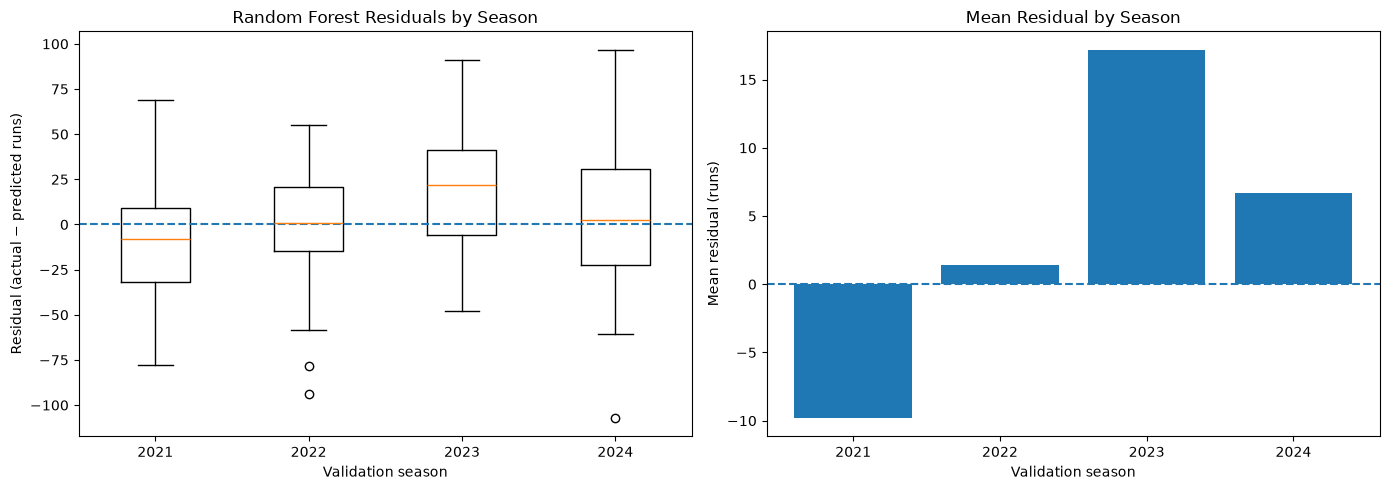

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residual distributions
season_order = sorted(rf_residuals_df["season"].unique())
residual_groups = [
    rf_residuals_df.loc[
        rf_residuals_df["season"] == season, "residual"
    ].to_numpy()
    for season in season_order
]

axes[0].boxplot(residual_groups, tick_labels=season_order)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Random Forest Residuals by Season")
axes[0].set_xlabel("Validation season")
axes[0].set_ylabel("Residual (actual − predicted runs)")

# Mean residual by season
mean_residuals = (
    rf_residuals_df.groupby("season")["residual"].mean()
)

axes[1].bar(mean_residuals.index.astype(str), mean_residuals.values)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Mean Residual by Season")
axes[1].set_xlabel("Validation season")
axes[1].set_ylabel("Mean residual (runs)")

plt.tight_layout()
plt.show()

In [87]:
rf_residuals_df["score_band"] = pd.cut(
    rf_residuals_df["actual_runs"],
    bins=[0, 120, 160, 200, float("inf")],
    labels=["Low (<=120)", "Moderate (121-160)",
            "High (161-200)", "Very high (>200)"],
    include_lowest=True,
)

score_error_analysis = (
    rf_residuals_df
    .groupby("score_band", observed=False)
    .agg(
        matches=("actual_runs", "size"),
        mean_actual=("actual_runs", "mean"),
        mean_predicted=("predicted_runs", "mean"),
        mean_residual=("residual", "mean"),
        MAE=("absolute_error", "mean"),
        RMSE=("residual", lambda s: np.sqrt(np.mean(s**2))),
    )
    .round(2)
)

display(score_error_analysis)

,matches,mean_actual,mean_predicted,mean_residual,MAE,RMSE
score_band,,,,,,
Low (<=120),11,102.09,169.53,-67.44,67.44,70.43
Moderate (121-160),79,144.09,169.14,-25.05,25.15,29.30
High (161-200),124,179.94,172.26,7.68,14.31,17.81
Very high (>200),65,221.34,174.67,46.67,46.67,50.06


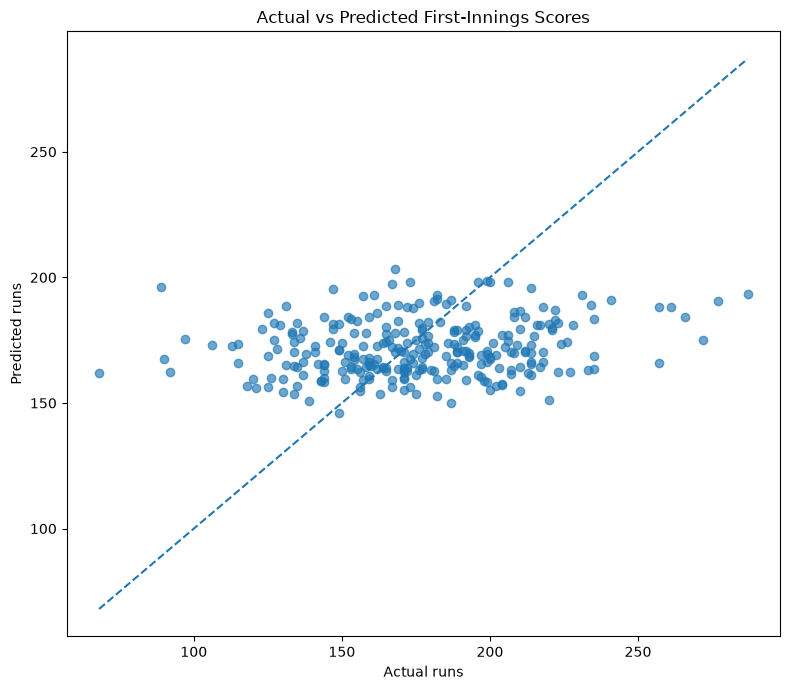

In [88]:
fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(
    rf_residuals_df["actual_runs"],
    rf_residuals_df["predicted_runs"],
    alpha=0.65,
)

# Perfect predictions lie on this diagonal.
score_min = min(
    rf_residuals_df["actual_runs"].min(),
    rf_residuals_df["predicted_runs"].min(),
)
score_max = max(
    rf_residuals_df["actual_runs"].max(),
    rf_residuals_df["predicted_runs"].max(),
)

ax.plot(
    [score_min, score_max],
    [score_min, score_max],
    linestyle="--",
)

ax.set_title("Actual vs Predicted First-Innings Scores")
ax.set_xlabel("Actual runs")
ax.set_ylabel("Predicted runs")

plt.tight_layout()
plt.show()

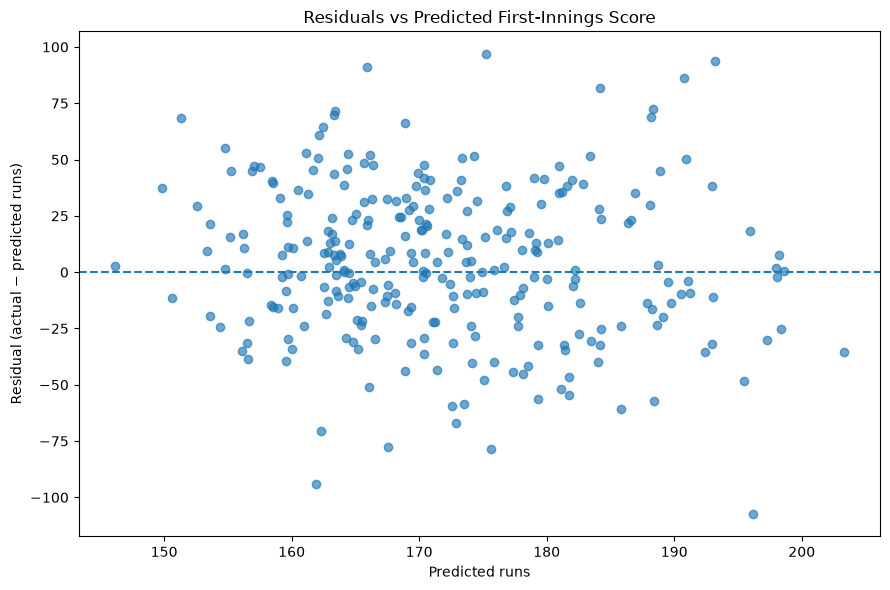

In [89]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    rf_residuals_df["predicted_runs"],
    rf_residuals_df["residual"],
    alpha=0.65,
)

ax.axhline(0, linestyle="--")
ax.set_title("Residuals vs Predicted First-Innings Score")
ax.set_xlabel("Predicted runs")
ax.set_ylabel("Residual (actual − predicted runs)")

plt.tight_layout()
plt.show()

In [90]:
residual_diagnostics = (
    rf_residuals_df
    .groupby("season")
    .agg(
        matches=("residual", "size"),
        mean_residual=("residual", "mean"),
        median_residual=("residual", "median"),
        residual_std=("residual", "std"),
        MAE=("absolute_error", "mean"),
        RMSE=("residual", lambda s: np.sqrt(np.mean(s**2))),
    )
)

display(residual_diagnostics.round(3))

,matches,mean_residual,median_residual,residual_std,MAE,RMSE
season,,,,,,
2021,60,-9.808,-8.196,32.593,26.781,33.776
2022,74,1.415,1.035,29.071,22.386,28.908
2023,74,17.188,21.899,29.667,28.727,34.113
2024,71,6.716,2.343,38.730,30.245,39.039


In [91]:
# Aggregate matches by date so every match on the same date
# receives a feature based only on earlier dates.
daily_scores = (
    modeling_df.groupby("date", as_index=False)
    .agg(
        daily_mean_score=("first_innings_runs", "mean"),
        daily_match_count=("first_innings_runs", "size"),
    )
    .sort_values("date")
    .reset_index(drop=True)
)

# Previous 30 distinct match dates, excluding the current date.
daily_scores["recent_environment_mean"] = (
    daily_scores["daily_mean_score"]
    .shift(1)
    .rolling(window=30, min_periods=5)
    .mean()
)

# Attach the historical scoring environment to every match.
environment_features = modeling_df.merge(
    daily_scores[["date", "recent_environment_mean"]],
    on="date",
    how="left",
    validate="many_to_one",
)

print("Matches:", len(environment_features))
print(
    "Missing recent-environment features:",
    environment_features["recent_environment_mean"].isna().sum(),
)

display(
    environment_features[
        ["date", "season", "first_innings_runs", "recent_environment_mean"]
    ].head(15)
)

Matches: 1243
Missing recent-environment features: 7


,date,season,first_innings_runs,recent_environment_mean
0,2008-04-18,2008,222,NaN
1,2008-04-19,2008,240,NaN
2,2008-04-19,2008,129,NaN
3,2008-04-20,2008,165,NaN
4,2008-04-20,2008,110,NaN
5,2008-04-21,2008,166,NaN
6,2008-04-22,2008,142,NaN
7,2008-04-23,2008,208,170.400000
8,2008-04-24,2008,214,176.666667
9,2008-04-25,2008,182,182.000000


In [94]:
environment_features = match_features_df.merge(
    daily_scores[["date", "recent_environment_mean"]],
    on="date",
    how="left",
    validate="many_to_one",
)

print("Dataset shape:", environment_features.shape)

required_columns = environment_plus_features + [target, "date"]
missing_columns = [
    col for col in required_columns
    if col not in environment_features.columns
]

print("Missing required columns:", missing_columns)

display(
    environment_features[
        ["date", "season", "venue_standardized",
         "first_batting_team", "opponent",
         "first_innings_runs", "recent_environment_mean"]
    ].head(10)
)

Dataset shape: (1243, 26)
Missing required columns: []


,date,season,venue_standardized,first_batting_team,opponent,first_innings_runs,recent_environment_mean
0,2008-04-18,2008,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,222,NaN
1,2008-04-19,2008,"Punjab Cricket Association Stadium, Mohali",Chennai Super Kings,Kings XI Punjab,240,NaN
2,2008-04-19,2008,Arun Jaitley Stadium,Rajasthan Royals,Delhi Daredevils,129,NaN
3,2008-04-20,2008,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,165,NaN
4,2008-04-20,2008,Eden Gardens,Deccan Chargers,Kolkata Knight Riders,110,NaN
5,2008-04-21,2008,Sawai Mansingh Stadium,Kings XI Punjab,Rajasthan Royals,166,NaN
6,2008-04-22,2008,Rajiv Gandhi International Stadium,Deccan Chargers,Delhi Daredevils,142,NaN
7,2008-04-23,2008,MA Chidambaram Stadium,Chennai Super Kings,Mumbai Indians,208,170.400000
8,2008-04-24,2008,Rajiv Gandhi International Stadium,Deccan Chargers,Rajasthan Royals,214,176.666667
9,2008-04-25,2008,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Mumbai Indians,182,182.000000


In [95]:
environment_model_results = []

environment_base_features = champion_features.copy()
environment_plus_features = (
    environment_base_features + ["recent_environment_mean"]
)

for model_name, features in {
    "standardized_base": environment_base_features,
    "base_plus_recent_environment": environment_plus_features,
}.items():

    numeric_features = [
        "season",
        "batting_team_won_toss",
    ]
    if "recent_environment_mean" in features:
        numeric_features.append("recent_environment_mean")

    categorical_features = [
        col for col in features if col not in numeric_features
    ]

    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_features),

        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=400,
            min_samples_leaf=4,
            max_features=0.8,
            random_state=42,
            n_jobs=-1,
        )),
    ])

    for fold in validation_folds:
        train_mask = (
            (environment_features["season"] <= fold["train_through"])
            & (
                environment_features["date"]
                < pd.Timestamp(f"{fold['validate_season']}-01-01")
            )
        )
        valid_mask = (
            environment_features["season"] == fold["validate_season"]
        )

        X_train = environment_features.loc[train_mask, features]
        y_train = environment_features.loc[train_mask, target]
        X_valid = environment_features.loc[valid_mask, features]
        y_valid = environment_features.loc[valid_mask, target]

        fitted_model = clone(model)
        fitted_model.fit(X_train, y_train)
        predictions = fitted_model.predict(X_valid)

        environment_model_results.append({
            "model": model_name,
            "validation_season": fold["validate_season"],
            "MAE": mean_absolute_error(y_valid, predictions),
            "RMSE": root_mean_squared_error(y_valid, predictions),
        })

environment_model_results_df = pd.DataFrame(environment_model_results)

print("Results by season:")
display(environment_model_results_df.round(3))

print("\nAverage performance:")
display(
    environment_model_results_df.groupby("model")
    .agg(
        average_MAE=("MAE", "mean"),
        average_RMSE=("RMSE", "mean"),
        worst_season_MAE=("MAE", "max"),
    )
    .round(3)
)

Results by season:


,model,validation_season,MAE,RMSE
0,standardized_base,2021,26.781,33.776
1,standardized_base,2022,22.386,28.908
2,standardized_base,2023,28.727,34.113
3,standardized_base,2024,30.245,39.039
4,base_plus_recent_environment,2021,27.682,34.818
5,base_plus_recent_environment,2022,23.016,29.037
6,base_plus_recent_environment,2023,36.458,43.350
7,base_plus_recent_environment,2024,29.866,38.707



Average performance:


,average_MAE,average_RMSE,worst_season_MAE
model,,,
base_plus_recent_environment,29.255,36.478,36.458
standardized_base,27.035,33.959,30.245


In [96]:

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

gb_results = []

numeric_features = ["season", "batting_team_won_toss"]
categorical_features = [
    col for col in champion_features
    if col not in numeric_features
]

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.04,
        max_depth=2,
        min_samples_leaf=8,
        loss="huber",
        random_state=42
    ))
])

for fold in validation_folds:
    train_mask = (
        (environment_features["season"] <= fold["train_through"])
        & (
            environment_features["date"]
            < pd.Timestamp(f"{fold['validate_season']}-01-01")
        )
    )
    valid_mask = (
        environment_features["season"] == fold["validate_season"]
    )

    X_train = environment_features.loc[train_mask, champion_features]
    y_train = environment_features.loc[train_mask, target]
    X_valid = environment_features.loc[valid_mask, champion_features]
    y_valid = environment_features.loc[valid_mask, target]

    model = clone(gb_pipeline)
    model.fit(X_train, y_train)
    predictions = model.predict(X_valid)

    gb_results.append({
        "validation_season": fold["validate_season"],
        "MAE": mean_absolute_error(y_valid, predictions),
        "RMSE": root_mean_squared_error(y_valid, predictions),
        "prediction_std": predictions.std()
    })

gb_results_df = pd.DataFrame(gb_results)

display(gb_results_df.round(3))

print("Average and worst-season performance:")
display(pd.DataFrame([{
    "average_MAE": gb_results_df["MAE"].mean(),
    "average_RMSE": gb_results_df["RMSE"].mean(),
    "worst_season_MAE": gb_results_df["MAE"].max()
}]).round(3))


,validation_season,MAE,RMSE,prediction_std
0,2021,26.375,32.891,2.561
1,2022,22.931,29.280,2.256
2,2023,28.366,33.788,2.733
3,2024,29.990,38.966,5.967


Average and worst-season performance:


,average_MAE,average_RMSE,worst_season_MAE
0,26.915,33.731,29.99


In [98]:

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor

# Rebuild the Random Forest champion explicitly
numeric_features = ["season", "batting_team_won_toss"]
categorical_features = [
    col for col in champion_features
    if col not in numeric_features
]

rf_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

rf_pipeline = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=4,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

spread_results = []

for fold in validation_folds:
    train_mask = (
        (environment_features["season"] <= fold["train_through"])
        & (
            environment_features["date"]
            < pd.Timestamp(f"{fold['validate_season']}-01-01")
        )
    )
    valid_mask = (
        environment_features["season"] == fold["validate_season"]
    )

    X_train = environment_features.loc[train_mask, champion_features]
    y_train = environment_features.loc[train_mask, target]
    X_valid = environment_features.loc[valid_mask, champion_features]
    y_valid = environment_features.loc[valid_mask, target]

    rf = clone(rf_pipeline).fit(X_train, y_train)
    gb = clone(gb_pipeline).fit(X_train, y_train)

    rf_pred = rf.predict(X_valid)
    gb_pred = gb.predict(X_valid)

    spread_results.append({
        "season": fold["validate_season"],
        "actual_std": y_valid.std(),
        "RF_prediction_std": rf_pred.std(),
        "GB_prediction_std": gb_pred.std(),
        "RF_MAE": mean_absolute_error(y_valid, rf_pred),
        "GB_MAE": mean_absolute_error(y_valid, gb_pred)
    })

spread_results_df = pd.DataFrame(spread_results)
display(spread_results_df.round(3))


,season,actual_std,RF_prediction_std,GB_prediction_std,RF_MAE,GB_MAE
0,2021,31.498,8.878,2.561,26.781,26.375
1,2022,29.048,7.620,2.256,22.386,22.931
2,2023,30.857,7.304,2.733,28.727,28.366
3,2024,38.543,11.198,5.967,30.245,29.990


In [99]:

range_results = []

for fold in validation_folds:
    train_mask = (
        (environment_features["season"] <= fold["train_through"])
        & (
            environment_features["date"]
            < pd.Timestamp(f"{fold['validate_season']}-01-01")
        )
    )
    valid_mask = (
        environment_features["season"] == fold["validate_season"]
    )

    X_train = environment_features.loc[train_mask, champion_features]
    y_train = environment_features.loc[train_mask, target]
    X_valid = environment_features.loc[valid_mask, champion_features]
    y_valid = environment_features.loc[valid_mask, target]

    rf = clone(rf_pipeline).fit(X_train, y_train)
    gb = clone(gb_pipeline).fit(X_train, y_train)

    rf_pred = rf.predict(X_valid)
    gb_pred = gb.predict(X_valid)

    range_results.append({
        "season": fold["validate_season"],
        "actual_min": y_valid.min(),
        "actual_max": y_valid.max(),
        "RF_pred_min": rf_pred.min(),
        "RF_pred_max": rf_pred.max(),
        "GB_pred_min": gb_pred.min(),
        "GB_pred_max": gb_pred.max(),
        "RF_MAE": mean_absolute_error(y_valid, rf_pred),
        "GB_MAE": mean_absolute_error(y_valid, gb_pred)
    })

range_results_df = pd.DataFrame(range_results)
display(range_results_df.round(2))


,season,actual_min,actual_max,RF_pred_min,RF_pred_max,GB_pred_min,GB_pred_max,RF_MAE,GB_MAE
0,2021,90,235,146.15,182.51,162.42,173.98,26.78,26.37
1,2022,68,222,154.79,188.43,161.45,172.12,22.39,22.93
2,2023,118,257,150.62,183.38,161.86,173.96,28.73,28.37
3,2024,89,287,153.40,203.28,169.96,193.73,30.25,29.99


In [100]:

print("Delivery columns:")
print(deliveries_df.columns.tolist())

print("\nAvailable innings labels:")
display(
    deliveries_df["innings_name"]
    .value_counts(dropna=False)
    .to_frame("delivery_records")
)

print("\nSample deliveries:")
display(deliveries_df.head(10))

print("\nMatch-level feature columns:")
print(match_features_df.columns.tolist())


Delivery columns:
['match_id', 'date', 'innings', 'innings_name', 'delivery_sequence', 'delivery_label', 'batting_team', 'batter', 'bowler', 'batter_runs', 'total_runs', 'extras', 'wides', 'noballs', 'byes', 'legbyes', 'penalty', 'wicket_count', 'wicket_details', 'run_reconciliation_difference', 'is_super_over', 'is_regular_innings']

Available innings labels:


,delivery_records
innings_name,
1st innings,153254
2nd innings,142303
Mumbai Indians Super Over,28
Kolkata Knight Riders Super Over,24
Kings XI Punjab Super Over,24
Sunrisers Hyderabad Super Over,20
Rajasthan Royals Super Over,20
Delhi Capitals Super Over,19
Royal Challengers Bangalore Super Over,18



Sample deliveries:


,match_id,date,innings,innings_name,delivery_sequence,delivery_label,batting_team,batter,bowler,batter_runs,...,wides,noballs,byes,legbyes,penalty,wicket_count,wicket_details,run_reconciliation_difference,is_super_over,is_regular_innings
0,1082591,2017-04-05,1,1st innings,1,0.1,Sunrisers Hyderabad,DA Warner,TS Mills,0,...,0,0,0,0,0,0,[],0,False,True
1,1082591,2017-04-05,1,1st innings,2,0.2,Sunrisers Hyderabad,DA Warner,TS Mills,0,...,0,0,0,0,0,0,[],0,False,True
2,1082591,2017-04-05,1,1st innings,3,0.3,Sunrisers Hyderabad,DA Warner,TS Mills,4,...,0,0,0,0,0,0,[],0,False,True
3,1082591,2017-04-05,1,1st innings,4,0.4,Sunrisers Hyderabad,DA Warner,TS Mills,0,...,0,0,0,0,0,0,[],0,False,True
4,1082591,2017-04-05,1,1st innings,5,0.5,Sunrisers Hyderabad,DA Warner,TS Mills,0,...,2,0,0,0,0,0,[],0,False,True
5,1082591,2017-04-05,1,1st innings,6,0.5,Sunrisers Hyderabad,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,[],0,False,True
6,1082591,2017-04-05,1,1st innings,7,0.6,Sunrisers Hyderabad,S Dhawan,TS Mills,0,...,0,0,0,1,0,0,[],0,False,True
7,1082591,2017-04-05,1,1st innings,8,1.1,Sunrisers Hyderabad,S Dhawan,A Choudhary,1,...,0,0,0,0,0,0,[],0,False,True
8,1082591,2017-04-05,1,1st innings,9,1.2,Sunrisers Hyderabad,DA Warner,A Choudhary,4,...,0,0,0,0,0,0,[],0,False,True
9,1082591,2017-04-05,1,1st innings,10,1.3,Sunrisers Hyderabad,DA Warner,A Choudhary,0,...,0,1,0,0,0,0,[],0,False,True



Match-level feature columns:
['match_id', 'date', 'season', 'competition', 'match_type', 'venue', 'city', 'team_1', 'team_2', 'toss_winner', 'toss_decision', 'first_batting_team', 'first_innings_runs', 'second_batting_team', 'second_innings_runs', 'winner', 'outcome_result', 'eliminator_winner', 'has_first_innings', 'has_second_innings', 'match_result_type', 'rolling_baseline_prediction', 'opponent', 'batting_team_won_toss', 'venue_standardized']


In [101]:

regular_deliveries = deliveries_df[
    deliveries_df["is_regular_innings"].eq(True)
].copy()

first_innings_deliveries = regular_deliveries[
    regular_deliveries["innings"].eq(1)
].copy()

delivery_match_audit = (
    first_innings_deliveries
    .groupby("match_id")
    .agg(
        delivery_records=("delivery_sequence", "size"),
        total_runs_from_deliveries=("total_runs", "sum"),
        batting_teams=("batting_team", "nunique"),
        batters=("batter", "nunique"),
        bowlers=("bowler", "nunique"),
        wicket_events=("wicket_count", "sum")
    )
    .reset_index()
)

score_targets = match_features_df[
    ["match_id", "first_innings_runs", "date", "season"]
].copy()

coverage_audit = score_targets.merge(
    delivery_match_audit,
    on="match_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Modeling matches:", len(score_targets))
print("Matches with first-innings delivery data:",
      coverage_audit["_merge"].eq("both").sum())
print("Matches without first-innings delivery data:",
      coverage_audit["_merge"].eq("left_only").sum())
print("Matches with run-total mismatch:",
      (
          coverage_audit["first_innings_runs"].notna()
          & coverage_audit["total_runs_from_deliveries"].notna()
          & (
              coverage_audit["first_innings_runs"]
              != coverage_audit["total_runs_from_deliveries"]
          )
      ).sum())

display(
    coverage_audit.loc[
        coverage_audit["_merge"].eq("both"),
        [
            "match_id", "season", "first_innings_runs",
            "total_runs_from_deliveries", "delivery_records",
            "batting_teams", "batters", "bowlers", "wicket_events"
        ]
    ].head(10)
)


Modeling matches: 1243
Matches with first-innings delivery data: 1243
Matches without first-innings delivery data: 0
Matches with run-total mismatch: 0


,match_id,season,first_innings_runs,total_runs_from_deliveries,delivery_records,batting_teams,batters,bowlers,wicket_events
0,335982,2008,222,222,124,1,5,6,3
1,335983,2008,240,240,124,1,7,7,5
2,335984,2008,129,129,122,1,10,5,8
3,335985,2008,165,165,123,1,8,6,7
4,335986,2008,110,110,118,1,10,6,10
5,335987,2008,166,166,122,1,10,7,8
6,335988,2008,142,142,122,1,10,5,8
7,335989,2008,208,208,127,1,7,8,5
8,335990,2008,214,214,126,1,6,7,5
9,335991,2008,182,182,124,1,11,6,10


In [102]:

# One row per historical match, with the first-innings team and score
history = match_features_df[
    [
        "match_id", "date", "season",
        "first_batting_team", "venue_standardized",
        "first_innings_runs"
    ]
].copy()

history = history.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

# Shift first, then calculate rolling averages from previous matches only
history["team_prior_avg_score"] = (
    history.groupby("first_batting_team")["first_innings_runs"]
    .transform(lambda s: s.shift(1).expanding(min_periods=1).mean())
)

history["venue_prior_avg_score"] = (
    history.groupby("venue_standardized")["first_innings_runs"]
    .transform(lambda s: s.shift(1).expanding(min_periods=1).mean())
)

print("Rows:", len(history))
print("First-match team history missing:",
      history["team_prior_avg_score"].isna().sum())
print("First-match venue history missing:",
      history["venue_prior_avg_score"].isna().sum())

display(
    history[
        [
            "date", "first_batting_team", "venue_standardized",
            "first_innings_runs", "team_prior_avg_score",
            "venue_prior_avg_score"
        ]
    ].head(15).round(2)
)


Rows: 1243
First-match team history missing: 19
First-match venue history missing: 49


C:\Users\amitb\AppData\Local\Temp\ipykernel_34352\148518617.py:38: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(2)


,date,first_batting_team,venue_standardized,first_innings_runs,team_prior_avg_score,venue_prior_avg_score
0,2008-04-18,Kolkata Knight Riders,M Chinnaswamy Stadium,222,NaN,NaN
1,2008-04-19,Chennai Super Kings,"Punjab Cricket Association Stadium, Mohali",240,NaN,NaN
2,2008-04-19,Rajasthan Royals,Arun Jaitley Stadium,129,NaN,NaN
3,2008-04-20,Mumbai Indians,Wankhede Stadium,165,NaN,NaN
4,2008-04-20,Deccan Chargers,Eden Gardens,110,NaN,NaN
5,2008-04-21,Kings XI Punjab,Sawai Mansingh Stadium,166,NaN,NaN
6,2008-04-22,Deccan Chargers,Rajiv Gandhi International Stadium,142,110.0,NaN
7,2008-04-23,Chennai Super Kings,MA Chidambaram Stadium,208,240.0,NaN
8,2008-04-24,Deccan Chargers,Rajiv Gandhi International Stadium,214,126.0,142.0
9,2008-04-25,Kings XI Punjab,"Punjab Cricket Association Stadium, Mohali",182,166.0,240.0


In [103]:

history = match_features_df[
    [
        "match_id", "date", "season",
        "first_batting_team", "venue_standardized",
        "first_innings_runs"
    ]
].copy()

history["date"] = pd.to_datetime(history["date"])
history = history.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

# Aggregate scores by date and group first, so same-day matches
# cannot influence one another's historical features.
team_daily_history = (
    history.groupby(["first_batting_team", "date"], as_index=False)
    ["first_innings_runs"].mean()
    .sort_values(["first_batting_team", "date"])
)

team_daily_history["team_prior_avg_score"] = (
    team_daily_history.groupby("first_batting_team")["first_innings_runs"]
    .transform(lambda s: s.shift(1).expanding(min_periods=1).mean())
)

venue_daily_history = (
    history.groupby(["venue_standardized", "date"], as_index=False)
    ["first_innings_runs"].mean()
    .sort_values(["venue_standardized", "date"])
)

venue_daily_history["venue_prior_avg_score"] = (
    venue_daily_history.groupby("venue_standardized")["first_innings_runs"]
    .transform(lambda s: s.shift(1).expanding(min_periods=1).mean())
)

history = history.merge(
    team_daily_history[
        ["first_batting_team", "date", "team_prior_avg_score"]
    ],
    on=["first_batting_team", "date"],
    how="left",
    validate="many_to_one"
)

history = history.merge(
    venue_daily_history[
        ["venue_standardized", "date", "venue_prior_avg_score"]
    ],
    on=["venue_standardized", "date"],
    how="left",
    validate="many_to_one"
)

print("Rows:", len(history))
print("Missing team history:", history["team_prior_avg_score"].isna().sum())
print("Missing venue history:", history["venue_prior_avg_score"].isna().sum())

display(
    history[
        [
            "date", "first_batting_team", "venue_standardized",
            "first_innings_runs", "team_prior_avg_score",
            "venue_prior_avg_score"
        ]
    ].head(15).round(2)
)


Rows: 1243
Missing team history: 19
Missing venue history: 52


C:\Users\amitb\AppData\Local\Temp\ipykernel_34352\335370400.py:67: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(2)


,date,first_batting_team,venue_standardized,first_innings_runs,team_prior_avg_score,venue_prior_avg_score
0,2008-04-18,Kolkata Knight Riders,M Chinnaswamy Stadium,222,NaN,NaN
1,2008-04-19,Chennai Super Kings,"Punjab Cricket Association Stadium, Mohali",240,NaN,NaN
2,2008-04-19,Rajasthan Royals,Arun Jaitley Stadium,129,NaN,NaN
3,2008-04-20,Mumbai Indians,Wankhede Stadium,165,NaN,NaN
4,2008-04-20,Deccan Chargers,Eden Gardens,110,NaN,NaN
5,2008-04-21,Kings XI Punjab,Sawai Mansingh Stadium,166,NaN,NaN
6,2008-04-22,Deccan Chargers,Rajiv Gandhi International Stadium,142,110.0,NaN
7,2008-04-23,Chennai Super Kings,MA Chidambaram Stadium,208,240.0,NaN
8,2008-04-24,Deccan Chargers,Rajiv Gandhi International Stadium,214,126.0,142.0
9,2008-04-25,Kings XI Punjab,"Punjab Cricket Association Stadium, Mohali",182,166.0,240.0


In [104]:

history_features = history[
    [
        "match_id",
        "team_prior_avg_score",
        "venue_prior_avg_score"
    ]
].copy()

model_features_df = match_features_df.merge(
    history_features,
    on="match_id",
    how="left",
    validate="one_to_one"
)

print("Rows preserved:", len(model_features_df) == len(match_features_df))
print("Duplicate match IDs:", model_features_df["match_id"].duplicated().sum())
print(
    "Missing historical features:",
    model_features_df[
        ["team_prior_avg_score", "venue_prior_avg_score"]
    ].isna().sum().to_dict()
)

display(
    model_features_df[
        [
            "date", "first_batting_team", "venue_standardized",
            "first_innings_runs", "team_prior_avg_score",
            "venue_prior_avg_score"
        ]
    ].head(10).round(2)
)


Rows preserved: True
Duplicate match IDs: 0
Missing historical features: {'team_prior_avg_score': 19, 'venue_prior_avg_score': 52}


C:\Users\amitb\AppData\Local\Temp\ipykernel_34352\1873523408.py:32: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,date,first_batting_team,venue_standardized,first_innings_runs,team_prior_avg_score,venue_prior_avg_score
0,2008-04-18,Kolkata Knight Riders,M Chinnaswamy Stadium,222,NaN,NaN
1,2008-04-19,Chennai Super Kings,"Punjab Cricket Association Stadium, Mohali",240,NaN,NaN
2,2008-04-19,Rajasthan Royals,Arun Jaitley Stadium,129,NaN,NaN
3,2008-04-20,Mumbai Indians,Wankhede Stadium,165,NaN,NaN
4,2008-04-20,Deccan Chargers,Eden Gardens,110,NaN,NaN
5,2008-04-21,Kings XI Punjab,Sawai Mansingh Stadium,166,NaN,NaN
6,2008-04-22,Deccan Chargers,Rajiv Gandhi International Stadium,142,110.0,NaN
7,2008-04-23,Chennai Super Kings,MA Chidambaram Stadium,208,240.0,NaN
8,2008-04-24,Deccan Chargers,Rajiv Gandhi International Stadium,214,126.0,142.0
9,2008-04-25,Kings XI Punjab,"Punjab Cricket Association Stadium, Mohali",182,166.0,240.0


In [105]:

from sklearn.base import clone

history_model_results = []

feature_sets = {
    "standardized_base": champion_features,
    "base_plus_history": champion_features + [
        "team_prior_avg_score",
        "venue_prior_avg_score"
    ]
}

for model_name, features in feature_sets.items():
    for fold in validation_folds:
        train_mask = (
            (model_features_df["season"] <= fold["train_through"])
            & (
                model_features_df["date"]
                < pd.Timestamp(f"{fold['validate_season']}-01-01")
            )
        )
        valid_mask = (
            model_features_df["season"] == fold["validate_season"]
        )

        X_train = model_features_df.loc[train_mask, features]
        y_train = model_features_df.loc[train_mask, target]
        X_valid = model_features_df.loc[valid_mask, features]
        y_valid = model_features_df.loc[valid_mask, target]

        numeric_cols = [
            col for col in features
            if col in [
                "season", "batting_team_won_toss",
                "team_prior_avg_score", "venue_prior_avg_score"
            ]
        ]
        categorical_cols = [
            col for col in features if col not in numeric_cols
        ]

        preprocessor = ColumnTransformer([
            ("numeric", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), numeric_cols),

            ("categorical", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]), categorical_cols)
        ])

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", RandomForestRegressor(
                n_estimators=400,
                min_samples_leaf=4,
                max_features=0.8,
                random_state=42,
                n_jobs=-1
            ))
        ])

        fitted = clone(pipeline).fit(X_train, y_train)
        predictions = fitted.predict(X_valid)

        history_model_results.append({
            "model": model_name,
            "season": fold["validate_season"],
            "MAE": mean_absolute_error(y_valid, predictions),
            "RMSE": root_mean_squared_error(y_valid, predictions)
        })

history_results_df = pd.DataFrame(history_model_results)

display(
    history_results_df.pivot(
        index="season", columns="model", values="MAE"
    ).round(3)
)

display(
    history_results_df.groupby("model").agg(
        average_MAE=("MAE", "mean"),
        average_RMSE=("RMSE", "mean"),
        worst_season_MAE=("MAE", "max")
    ).round(3)
)


model,base_plus_history,standardized_base
season,,
2021,25.625,26.781
2022,24.115,22.386
2023,30.988,28.727
2024,31.347,30.245


,average_MAE,average_RMSE,worst_season_MAE
model,,,
base_plus_history,28.019,34.930,31.347
standardized_base,27.035,33.959,30.245


In [106]:

# Summarize first-innings team and bowling performance
# from completed historical matches.

regular_first = deliveries_df[
    deliveries_df["is_regular_innings"].eq(True)
    & deliveries_df["innings"].eq(1)
].copy()

team_batting_summary = (
    regular_first.groupby(["match_id", "batting_team"])
    .agg(
        runs=("total_runs", "sum"),
        wickets=("wicket_count", "sum"),
        delivery_records=("delivery_sequence", "size")
    )
    .reset_index()
)

team_bowling_summary = (
    regular_first.groupby(["match_id", "bowler"])
    .agg(
        runs_conceded=("total_runs", "sum"),
        wickets=("wicket_count", "sum"),
        delivery_records=("delivery_sequence", "size")
    )
    .reset_index()
)

print("Team-match batting records:", len(team_batting_summary))
print("Bowler-match records:", len(team_bowling_summary))
print("Teams represented:", team_batting_summary["batting_team"].nunique())
print("Bowlers represented:", team_bowling_summary["bowler"].nunique())

print("\nTeam batting summary:")
display(team_batting_summary.head(10))

print("\nBowler summary:")
display(team_bowling_summary.head(10))


Team-match batting records: 1243
Bowler-match records: 7379
Teams represented: 19
Bowlers represented: 522

Team batting summary:


,match_id,batting_team,runs,wickets,delivery_records
0,1082591,Sunrisers Hyderabad,207,4,125
1,1082592,Mumbai Indians,184,8,125
2,1082593,Gujarat Lions,183,4,122
3,1082594,Rising Pune Supergiant,163,6,125
4,1082595,Royal Challengers Bangalore,157,8,124
5,1082596,Gujarat Lions,135,7,120
6,1082597,Kolkata Knight Riders,178,7,128
7,1082598,Royal Challengers Bangalore,148,4,123
8,1082599,Delhi Daredevils,205,4,125
9,1082600,Sunrisers Hyderabad,158,8,126



Bowler summary:


,match_id,bowler,runs_conceded,wickets,delivery_records
0,1082591,A Choudhary,55,1,28
1,1082591,S Aravind,36,0,18
2,1082591,SR Watson,41,0,18
3,1082591,STR Binny,10,1,6
4,1082591,TM Head,11,0,6
5,1082591,TS Mills,32,1,25
6,1082591,YS Chahal,22,1,24
7,1082592,A Zampa,27,1,19
8,1082592,AB Dinda,58,1,27
9,1082592,BA Stokes,36,1,25


In [107]:

# Inspect the available wicket details and extras columns
print("Relevant columns:")
print([
    col for col in deliveries_df.columns
    if col in [
        "match_id", "innings", "bowler", "total_runs",
        "batter_runs", "extras", "wides", "noballs",
        "byes", "legbyes", "penalty", "wicket_count",
        "wicket_details", "is_regular_innings"
    ]
])

print("\nWicket detail examples:")
wicket_rows = regular_first[
    regular_first["wicket_count"] > 0
][["match_id", "bowler", "wicket_count", "wicket_details"]]

display(wicket_rows.head(15))

print("\nExtras summary:")
display(
    regular_first[
        ["wides", "noballs", "byes", "legbyes", "penalty"]
    ].sum().to_frame("total")
)


Relevant columns:
['match_id', 'innings', 'bowler', 'batter_runs', 'total_runs', 'extras', 'wides', 'noballs', 'byes', 'legbyes', 'penalty', 'wicket_count', 'wicket_details', 'is_regular_innings']

Wicket detail examples:


,match_id,bowler,wicket_count,wicket_details
11,1082591,A Choudhary,1,"[{'fielders': ['Mandeep Singh'], 'kind': 'caug..."
64,1082591,STR Binny,1,"[{'fielders': ['Sachin Baby'], 'kind': 'caught..."
94,1082591,YS Chahal,1,"[{'fielders': ['Sachin Baby'], 'kind': 'caught..."
116,1082591,TS Mills,1,"[{'kind': 'bowled', 'player_out': 'Yuvraj Sing..."
274,1082592,Imran Tahir,1,"[{'kind': 'bowled', 'player_out': 'PA Patel'}]"
287,1082592,Imran Tahir,1,"[{'kind': 'bowled', 'player_out': 'RG Sharma'}]"
289,1082592,Imran Tahir,1,"[{'kind': 'lbw', 'player_out': 'JC Buttler'}]"
316,1082592,R Bhatia,1,"[{'kind': 'caught and bowled', 'player_out': '..."
330,1082592,R Bhatia,1,"[{'fielders': ['MS Dhoni'], 'kind': 'caught', ..."
343,1082592,A Zampa,1,"[{'fielders': ['R Bhatia'], 'kind': 'caught', ..."



Extras summary:


,total
wides,6059
noballs,682
byes,745
legbyes,2976
penalty,0


In [108]:

import ast
import pandas as pd

def parse_wicket_details(value):
    if isinstance(value, list):
        return value
    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            return parsed if isinstance(parsed, list) else []
        except (ValueError, SyntaxError):
            return []
    return []

# Flatten wicket details into one row per dismissal
wicket_records = []

for _, row in regular_first.loc[
    regular_first["wicket_count"] > 0
].iterrows():
    for dismissal in parse_wicket_details(row["wicket_details"]):
        wicket_records.append({
            "match_id": row["match_id"],
            "bowler": row["bowler"],
            "kind": dismissal.get("kind", "unknown"),
            "player_out": dismissal.get("player_out")
        })

wicket_details_df = pd.DataFrame(wicket_records)

print("Dismissal categories:")
display(
    wicket_details_df["kind"]
    .value_counts(dropna=False)
    .to_frame("count")
)

# Runs that are usually charged to the bowler:
# total runs minus byes, leg-byes and penalty runs.
regular_first["bowler_charged_runs"] = (
    regular_first["total_runs"]
    - regular_first["byes"]
    - regular_first["legbyes"]
    - regular_first["penalty"]
)

print("\nBowler-charged run totals:")
print("Total innings runs:", regular_first["total_runs"].sum())
print("Bowler-charged runs:", regular_first["bowler_charged_runs"].sum())
print("Byes:", regular_first["byes"].sum())
print("Leg-byes:", regular_first["legbyes"].sum())
print("Penalty:", regular_first["penalty"].sum())


Dismissal categories:


,count
kind,
caught,4858
bowled,1234
run out,684
lbw,434
caught and bowled,204
stumped,186
hit wicket,8
retired hurt,8
retired out,3



Bowler-charged run totals:
Total innings runs: 209532
Bowler-charged runs: 205811
Byes: 745
Leg-byes: 2976
Penalty: 0


In [109]:

# Wicket types credited to the bowler
bowler_credited_dismissals = {
    "caught",
    "bowled",
    "lbw",
    "caught and bowled",
    "stumped",
    "hit wicket"
}

wicket_details_df["bowler_credited"] = (
    wicket_details_df["kind"].isin(bowler_credited_dismissals)
)

credited_wickets_by_match_bowler = (
    wicket_details_df.loc[wicket_details_df["bowler_credited"]]
    .groupby(["match_id", "bowler"])
    .size()
    .rename("credited_wickets")
    .reset_index()
)

# Aggregate runs and recorded deliveries for each bowler in each match
bowler_match = (
    regular_first.groupby(["match_id", "bowler"], as_index=False)
    .agg(
        runs_conceded=("bowler_charged_runs", "sum"),
        delivery_records=("delivery_sequence", "size"),
        wides=("wides", "sum"),
        noballs=("noballs", "sum")
    )
    .merge(
        credited_wickets_by_match_bowler,
        on=["match_id", "bowler"],
        how="left",
        validate="one_to_one"
    )
)

bowler_match["credited_wickets"] = (
    bowler_match["credited_wickets"].fillna(0).astype(int)
)

print("Bowler-match rows:", len(bowler_match))
print("Missing credited wickets:", bowler_match["credited_wickets"].isna().sum())
print("Total credited wickets:", bowler_match["credited_wickets"].sum())

display(bowler_match.head(15))


Bowler-match rows: 7379
Missing credited wickets: 0
Total credited wickets: 6924


,match_id,bowler,runs_conceded,delivery_records,wides,noballs,credited_wickets
0,1082591,A Choudhary,55,28,3,1,1
1,1082591,S Aravind,36,18,0,0,0
2,1082591,SR Watson,41,18,0,0,0
3,1082591,STR Binny,10,6,0,0,1
4,1082591,TM Head,11,6,0,0,0
5,1082591,TS Mills,31,25,2,0,1
6,1082591,YS Chahal,22,24,0,0,1
7,1082592,A Zampa,26,19,1,0,1
8,1082592,AB Dinda,57,27,3,0,0
9,1082592,BA Stokes,36,25,2,0,1


In [110]:

# Attach match date and the team batting first
match_lookup = match_features_df[
    ["match_id", "date", "first_batting_team", "second_batting_team"]
].copy()

bowler_match_dated = bowler_match.merge(
    match_lookup,
    on="match_id",
    how="left",
    validate="many_to_one"
)

# First-innings bowlers belong to the team batting second
bowler_match_dated["bowling_team"] = (
    bowler_match_dated["second_batting_team"]
)

team_bowling_match = (
    bowler_match_dated
    .groupby(["match_id", "date", "bowling_team"], as_index=False)
    .agg(
        runs_conceded=("runs_conceded", "sum"),
        credited_wickets=("credited_wickets", "sum"),
        bowlers_used=("bowler", "nunique")
    )
    .sort_values(["date", "match_id"])
    .reset_index(drop=True)
)

print("Team-match bowling rows:", len(team_bowling_match))
print("Missing bowling teams:", team_bowling_match["bowling_team"].isna().sum())

display(team_bowling_match.head(15))


Team-match bowling rows: 1237
Missing bowling teams: 0


,match_id,date,bowling_team,runs_conceded,credited_wickets,bowlers_used
0,335982,2008-04-18,Royal Challengers Bangalore,214,3,6
1,335983,2008-04-19,Kings XI Punjab,238,5,7
2,335984,2008-04-19,Delhi Daredevils,125,6,5
3,335985,2008-04-20,Royal Challengers Bangalore,157,5,6
4,335986,2008-04-20,Kolkata Knight Riders,106,9,6
5,335987,2008-04-21,Rajasthan Royals,165,7,7
6,335988,2008-04-22,Delhi Daredevils,139,7,5
7,335989,2008-04-23,Mumbai Indians,201,4,8
8,335990,2008-04-24,Rajasthan Royals,214,5,7
9,335991,2008-04-25,Mumbai Indians,180,8,6


In [111]:

team_bowling_match["date"] = pd.to_datetime(team_bowling_match["date"])

team_bowling_match = team_bowling_match.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

# Aggregate by team and date so same-day matches cannot leak into each other
team_bowling_daily = (
    team_bowling_match
    .groupby(["bowling_team", "date"], as_index=False)
    .agg(
        daily_runs_conceded=("runs_conceded", "mean"),
        daily_credited_wickets=("credited_wickets", "mean")
    )
    .sort_values(["bowling_team", "date"])
)

team_bowling_daily["prior_avg_runs_conceded"] = (
    team_bowling_daily.groupby("bowling_team")["daily_runs_conceded"]
    .transform(lambda s: s.shift(1).expanding(min_periods=1).mean())
)

team_bowling_daily["prior_avg_wickets"] = (
    team_bowling_daily.groupby("bowling_team")["daily_credited_wickets"]
    .transform(lambda s: s.shift(1).expanding(min_periods=1).mean())
)

# Join historical features back to each match
team_bowling_match = team_bowling_match.merge(
    team_bowling_daily[
        [
            "bowling_team", "date",
            "prior_avg_runs_conceded", "prior_avg_wickets"
        ]
    ],
    on=["bowling_team", "date"],
    how="left",
    validate="many_to_one"
)

print("Rows:", len(team_bowling_match))
print("Missing prior runs:", team_bowling_match["prior_avg_runs_conceded"].isna().sum())
print("Missing prior wickets:", team_bowling_match["prior_avg_wickets"].isna().sum())

display(
    team_bowling_match[
        [
            "date", "bowling_team", "runs_conceded",
            "credited_wickets", "prior_avg_runs_conceded",
            "prior_avg_wickets"
        ]
    ].head(15).round(2)
)


Rows: 1237
Missing prior runs: 19
Missing prior wickets: 19


C:\Users\amitb\AppData\Local\Temp\ipykernel_34352\1994407394.py:52: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(2)


,date,bowling_team,runs_conceded,credited_wickets,prior_avg_runs_conceded,prior_avg_wickets
0,2008-04-18,Royal Challengers Bangalore,214,3,NaN,NaN
1,2008-04-19,Kings XI Punjab,238,5,NaN,NaN
2,2008-04-19,Delhi Daredevils,125,6,NaN,NaN
3,2008-04-20,Royal Challengers Bangalore,157,5,214.0,3.0
4,2008-04-20,Kolkata Knight Riders,106,9,NaN,NaN
5,2008-04-21,Rajasthan Royals,165,7,NaN,NaN
6,2008-04-22,Delhi Daredevils,139,7,125.0,6.0
7,2008-04-23,Mumbai Indians,201,4,NaN,NaN
8,2008-04-24,Rajasthan Royals,214,5,165.0,7.0
9,2008-04-25,Mumbai Indians,180,8,201.0,4.0


In [112]:

bowling_history_features = team_bowling_match[
    [
        "match_id",
        "prior_avg_runs_conceded",
        "prior_avg_wickets"
    ]
].copy()

model_features_df = model_features_df.drop(
    columns=[
        "prior_avg_runs_conceded",
        "prior_avg_wickets"
    ],
    errors="ignore"
).merge(
    bowling_history_features,
    on="match_id",
    how="left",
    validate="one_to_one"
)

print("Rows preserved:", len(model_features_df) == len(match_features_df))
print("Duplicate match IDs:", model_features_df["match_id"].duplicated().sum())
print(
    "Missing bowling features:",
    model_features_df[
        ["prior_avg_runs_conceded", "prior_avg_wickets"]
    ].isna().sum().to_dict()
)

display(
    model_features_df[
        [
            "date", "first_batting_team", "opponent",
            "first_innings_runs", "prior_avg_runs_conceded",
            "prior_avg_wickets"
        ]
    ].head(15).round(2)
)


Rows preserved: True
Duplicate match IDs: 0
Missing bowling features: {'prior_avg_runs_conceded': 25, 'prior_avg_wickets': 25}


C:\Users\amitb\AppData\Local\Temp\ipykernel_34352\3251769377.py:38: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(2)


,date,first_batting_team,opponent,first_innings_runs,prior_avg_runs_conceded,prior_avg_wickets
0,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,222,NaN,NaN
1,2008-04-19,Chennai Super Kings,Kings XI Punjab,240,NaN,NaN
2,2008-04-19,Rajasthan Royals,Delhi Daredevils,129,NaN,NaN
3,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,165,214.0,3.0
4,2008-04-20,Deccan Chargers,Kolkata Knight Riders,110,NaN,NaN
5,2008-04-21,Kings XI Punjab,Rajasthan Royals,166,NaN,NaN
6,2008-04-22,Deccan Chargers,Delhi Daredevils,142,125.0,6.0
7,2008-04-23,Chennai Super Kings,Mumbai Indians,208,NaN,NaN
8,2008-04-24,Deccan Chargers,Rajasthan Royals,214,165.0,7.0
9,2008-04-25,Kings XI Punjab,Mumbai Indians,182,201.0,4.0


In [113]:

bowling_model_results = []

feature_sets = {
    "standardized_base": champion_features,
    "base_plus_bowling_history": champion_features + [
        "prior_avg_runs_conceded",
        "prior_avg_wickets"
    ]
}

for model_name, features in feature_sets.items():
    numeric_cols = [
        col for col in features
        if col in [
            "season", "batting_team_won_toss",
            "prior_avg_runs_conceded", "prior_avg_wickets"
        ]
    ]
    categorical_cols = [
        col for col in features if col not in numeric_cols
    ]

    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_cols),

        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols)
    ])

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=400,
            min_samples_leaf=4,
            max_features=0.8,
            random_state=42,
            n_jobs=-1
        ))
    ])

    for fold in validation_folds:
        train_mask = (
            (model_features_df["season"] <= fold["train_through"])
            & (
                model_features_df["date"]
                < pd.Timestamp(f"{fold['validate_season']}-01-01")
            )
        )
        valid_mask = (
            model_features_df["season"] == fold["validate_season"]
        )

        X_train = model_features_df.loc[train_mask, features]
        y_train = model_features_df.loc[train_mask, target]
        X_valid = model_features_df.loc[valid_mask, features]
        y_valid = model_features_df.loc[valid_mask, target]

        fitted = clone(pipeline).fit(X_train, y_train)
        predictions = fitted.predict(X_valid)

        bowling_model_results.append({
            "model": model_name,
            "season": fold["validate_season"],
            "MAE": mean_absolute_error(y_valid, predictions),
            "RMSE": root_mean_squared_error(y_valid, predictions)
        })

bowling_results_df = pd.DataFrame(bowling_model_results)

display(
    bowling_results_df.pivot(
        index="season", columns="model", values="MAE"
    ).round(3)
)

display(
    bowling_results_df.groupby("model").agg(
        average_MAE=("MAE", "mean"),
        average_RMSE=("RMSE", "mean"),
        worst_season_MAE=("MAE", "max")
    ).round(3)
)


model,base_plus_bowling_history,standardized_base
season,,
2021,27.179,26.781
2022,23.435,22.386
2023,29.434,28.727
2024,29.808,30.245


,average_MAE,average_RMSE,worst_season_MAE
model,,,
base_plus_bowling_history,27.464,34.264,29.808
standardized_base,27.035,33.959,30.245


In [114]:

from sklearn.base import clone

tuning_results = []

for min_leaf in [1, 2, 4, 8]:
    for fold in validation_folds:
        train_mask = (
            (model_features_df["season"] <= fold["train_through"])
            & (
                model_features_df["date"]
                < pd.Timestamp(f"{fold['validate_season']}-01-01")
            )
        )
        valid_mask = (
            model_features_df["season"] == fold["validate_season"]
        )

        X_train = model_features_df.loc[train_mask, champion_features]
        y_train = model_features_df.loc[train_mask, target]
        X_valid = model_features_df.loc[valid_mask, champion_features]
        y_valid = model_features_df.loc[valid_mask, target]

        model = clone(rf_pipeline)
        model.set_params(
            regressor__min_samples_leaf=min_leaf
        )
        model.fit(X_train, y_train)
        predictions = model.predict(X_valid)

        tuning_results.append({
            "min_samples_leaf": min_leaf,
            "season": fold["validate_season"],
            "MAE": mean_absolute_error(y_valid, predictions),
            "RMSE": root_mean_squared_error(y_valid, predictions),
            "prediction_std": predictions.std()
        })

tuning_results_df = pd.DataFrame(tuning_results)

display(
    tuning_results_df.pivot(
        index="season",
        columns="min_samples_leaf",
        values="MAE"
    ).round(3)
)

display(
    tuning_results_df.groupby("min_samples_leaf").agg(
        average_MAE=("MAE", "mean"),
        average_RMSE=("RMSE", "mean"),
        worst_season_MAE=("MAE", "max"),
        average_prediction_std=("prediction_std", "mean")
    ).round(3)
)


min_samples_leaf,1,2,4,8
season,,,,
2021,30.861,28.343,26.781,26.128
2022,23.326,22.709,22.386,22.457
2023,29.399,28.656,28.727,28.982
2024,32.530,32.000,30.245,29.286


,average_MAE,average_RMSE,worst_season_MAE,average_prediction_std
min_samples_leaf,,,,
1,29.029,36.080,32.530,13.203
2,27.927,34.908,32.000,11.340
4,27.035,33.959,30.245,8.750
8,26.713,33.708,29.286,6.502
